# TP3 — Black Friday Sales Prediction
## Parte 1: Predicción de ventas diarias

**Diplomatura en Ciencia de Datos (FAMAF 2026), Mentoría**
Rafael Pignata y Coti

Este notebook resuelve la primera parte del TP3: un problema supervisado de series de tiempo,
predecir las ventas totales diarias (`Daily_Sales`) de ABC Private Limited.

Se parte del dataset curado en el TP2 (`bf_dataset_temporal_curado.csv.gz`), que tiene una fila
por transacción. Acá se agrega a nivel día y se construyen las variables que va a usar el modelo.

Se trabaja con un horizonte de predicción de un día: para predecir las ventas de una fecha se
puede usar toda la información de fechas anteriores, como si ya estuviera disponible al momento
de predecir. El punto h) plantea un escenario distinto (predecir todo el 2024 de una sola vez, sin
ir recibiendo datos reales día a día) y se compara contra este esquema principal.

**Puntos a resolver:**
- a) Construcción de la tabla de modelado a nivel día
- b) Modelos de referencia (baseline estacional y SARIMA)
- c) Partición y estrategia de validación
- d) Modelos supervisados (Ridge y LightGBM)
- e) Evaluación sobre el conjunto de test (2024)
- f) Desempeño específico en Black Friday
- g) Interpretación de los modelos
- h) Predicción desde un único origen (forecast a 2024 completo)

In [6]:
# Celda: carga de datos
# El dataset curado en el TP2 tiene granularidad transaccional; para este punto hay que
# agregarlo a nivel día. Se lee directo desde el repositorio de GitHub, así corre igual en
# cualquier Colab o máquina con internet, sin montar Drive.
import pandas as pd
import numpy as np

from statsmodels.tsa.statespace.sarimax import SARIMAX

import matplotlib.pyplot as plt

import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit

from lightgbm import LGBMRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

URL_DATOS = ("https://raw.githubusercontent.com/RafaelPigata/RP_blackfriday_sales_prediction/"
             "main/datos/bf_dataset_temporal_curado.csv.gz")

df = pd.read_csv(URL_DATOS, compression="gzip", parse_dates=["Purchase_Date"])
df.shape

(1650204, 40)

In [7]:
PALETA = sns.color_palette("deep")

def millones(ax, eje="y"):
    """Formatea un eje en millones."""
    f = mticker.FuncFormatter(lambda v, p: f"{v/1e6:,.0f}M")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

## Datos de partida

Partimos del dataset curado en el TP2: **1.650.204 transacciones** (ver la salida de la celda de
carga), una fila por cada combinación de cliente, producto y fecha. Antes de construir cualquier
variable, confirmamos que la granularidad es efectivamente transaccional y que el rango de fechas
cubre los tres años completos, del 1 de enero de 2022 al 31 de diciembre de 2024 (celda
siguiente).

## a) Construcción de la tabla de modelado

El problema pide predecir `Daily_Sales`, la suma de `Purchase` por fecha. Esa es una variable a
nivel día, así que el primer paso es transformar el dataset transaccional en una tabla con una
fila por fecha.

A partir de esa tabla base vamos agregando, de a un bloque por vez, los grupos de variables que
sugiere el enunciado: calendario y estacionalidad, cercanía a Black Friday, contexto económico,
actividad comercial del día y comportamiento histórico de las ventas (lags y medias móviles). En
cada bloque explicamos qué se calculó y por qué.

Una distinción importante atraviesa todo este punto: las variables de calendario, cercanía a BF y
contexto económico se conocen de antemano, no hay riesgo de que se filtre información del futuro.
Las que dependen de las propias ventas (lags, medias móviles, mix de actividad) hay que
construirlas con cuidado para que, al predecir el día X, solo usen información de días anteriores
a X.

In [8]:
# Celda: chequeo rápido de la unidad de partida
# Confirmamos granularidad transaccional y el rango de fechas antes de agregar,
# para no dar por sentado nada del TP2.
df["Purchase_Date"].agg(["min", "max"])

min   2022-01-01
max   2024-12-31
Name: Purchase_Date, dtype: datetime64[ns]

Agregamos primero la variable objetivo (`Daily_Sales`, suma de `Purchase` por fecha) y una
variable auxiliar (`Transactions`, cantidad de transacciones por fecha), que sirve como predictora
y para diagnósticos más adelante.

In [9]:
# Celda: tabla base a nivel día
# Daily_Sales es la variable objetivo del punto 1a. Transactions queda como variable
# auxiliar (sirve como predictora y para armar el ticket promedio más adelante).
daily = (
    df.groupby("Purchase_Date")
    .agg(Daily_Sales=("Purchase", "sum"), Transactions=("Transaction_ID", "count"))
    .reset_index()
    .sort_values("Purchase_Date")
    .reset_index(drop=True)
)
daily.shape

(1096, 3)

La tabla queda con 1.096 filas (365 días de 2022, 365 de 2023 y 366 de 2024, que es bisiesto), tal
como se ve arriba.

In [10]:
daily

,Purchase_Date,Daily_Sales,Transactions
0,2022-01-01,10668768,1184
1,2022-01-02,11276225,1222
2,2022-01-03,8485441,919
3,2022-01-04,8808836,974
4,2022-01-05,8900576,938
...,...,...,...
1091,2024-12-27,21362470,1704
1092,2024-12-28,25684569,2084
1093,2024-12-29,25536623,2062
1094,2024-12-30,20024816,1585


### Calendario y estacionalidad

Agregamos día de la semana (`Dow`), mes, trimestre y una marca de fin de semana (`Is_Weekend`),
todas derivables directo de la fecha. Sumamos también una codificación cíclica de día de semana y
mes (seno y coseno): sin esa codificación, el modelo vería el domingo (6) y el lunes (0) como los
días más lejanos entre sí, cuando en realidad son consecutivos. Lo mismo pasa entre diciembre y
enero.

In [6]:
# Celda: variables de calendario
# Determinísticas: se conocen de antemano para cualquier fecha, no hay riesgo de leakage.
daily["Dow"] = daily["Purchase_Date"].dt.dayofweek
daily["Month"] = daily["Purchase_Date"].dt.month
daily["Quarter"] = daily["Purchase_Date"].dt.quarter
daily["Is_Weekend"] = (daily["Dow"] >= 5).astype(int)

# Codificación cíclica para no imponer una distancia artificial entre diciembre y enero,
# o entre domingo y lunes.
daily["Dow_Sin"] = np.sin(2 * np.pi * daily["Dow"] / 7)
daily["Dow_Cos"] = np.cos(2 * np.pi * daily["Dow"] / 7)
daily["Month_Sin"] = np.sin(2 * np.pi * daily["Month"] / 12)
daily["Month_Cos"] = np.cos(2 * np.pi * daily["Month"] / 12)
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025


### Cercanía a Black Friday

El TP2 ya había calculado, a nivel transacción, `Days_To_Black_Friday` (cuántos días faltan o
pasaron desde el BF de ese año, con signo), `Dias_Abs_BF` (la misma distancia sin signo) y
`En_Ventana_BF` (si la fecha cae dentro de la ventana del evento). Como son constantes dentro de
una misma fecha, alcanza con tomar el primer valor de cada día.

In [7]:
# Celda: cercanía a Black Friday
# Days_To_Black_Friday, Dias_Abs_BF y En_Ventana_BF ya están calculadas a nivel
# transacción en el TP2 y son constantes dentro de una misma fecha (dependen solo
# del día, no de la transacción). Lo verificamos antes de bajarlas a nivel día.
bf_por_dia = df.groupby("Purchase_Date")[["Days_To_Black_Friday", "Dias_Abs_BF", "En_Ventana_BF"]].nunique()
assert (bf_por_dia == 1).all().all(), "Alguna de estas variables varía dentro del mismo día"

bf_diario = df.groupby("Purchase_Date")[["Days_To_Black_Friday", "Dias_Abs_BF", "En_Ventana_BF"]].first()
daily = daily.merge(bf_diario, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos,Days_To_Black_Friday,Dias_Abs_BF,En_Ventana_BF
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025,-328,328,0
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025,-327,327,0
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025,-326,326,0
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025,-325,325,0
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025,-324,324,0


### Contexto económico

`CPI_Index`, `Monthly_Inflation_Rate`, `Consumer_Confidence_Index` y `Retail_Activity_Index` son
mensuales (constantes dentro del mes), así que se agregan por *merge* sobre el par año-mes.

Dejamos fuera `Category_Activity_Index`, porque está particionada por `Product_Category_1` y
llevarla a nivel día implicaría agregarla de alguna forma (por ejemplo ponderada por las ventas
del día). Preferimos no sumar ese supuesto extra a un primer modelo; si hiciera falta, se puede
retomar más adelante.

El enunciado habilita a suponer que las estimaciones de estas variables económicas para las
fechas a predecir están disponibles al momento de predecir, así que no hay problema de que sean
"del futuro".

In [8]:
# Celda: contexto económico mensual
# CPI_Index, Monthly_Inflation_Rate, Consumer_Confidence_Index y Retail_Activity_Index
# son mensuales y constantes dentro del mes; se agregan por merge sobre (año, mes).
# Category_Activity_Index queda fuera de este primer modelo por estar particionada por
# Product_Category_1 (decisión a revisar más adelante si hace falta).
df["Anio_Mes"] = df["Purchase_Date"].values.astype("datetime64[M]")
econ_mensual = (
    df.groupby("Anio_Mes")[["CPI_Index", "Monthly_Inflation_Rate", "Consumer_Confidence_Index", "Retail_Activity_Index"]]
    .first()
    .reset_index()
)

daily["Anio_Mes"] = daily["Purchase_Date"].values.astype("datetime64[M]")
daily = daily.merge(econ_mensual, on="Anio_Mes", how="left").drop(columns="Anio_Mes")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos,Days_To_Black_Friday,Dias_Abs_BF,En_Ventana_BF,CPI_Index,Monthly_Inflation_Rate,Consumer_Confidence_Index,Retail_Activity_Index
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025,-328,328,0,100.679,0.679,101.44,94.0
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025,-327,327,0,100.679,0.679,101.44,94.0
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025,-326,326,0,100.679,0.679,101.44,94.0
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025,-325,325,0,100.679,0.679,101.44,94.0
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025,-324,324,0,100.679,0.679,101.44,94.0


### Actividad comercial del día

Sumamos la proporción de transacciones por canal (`Prop_Online`, `Prop_Store`) y la cantidad de
clientes y productos únicos que compraron ese día. Estas variables se construyen contando
transacciones, nunca sumando `Purchase`, así no hay riesgo de que se cuele información del propio
monto que se quiere predecir.

In [9]:
# Celda: mix de actividad del día
# Variables descriptivas construidas agregando transacciones, sin usar Purchase del
# propio día como insumo (para no meter leakage circular).
canal = (
    df.groupby(["Purchase_Date", "Sales_Channel"])
    .size()
    .unstack(fill_value=0)
)
canal_prop = canal.div(canal.sum(axis=1), axis=0).add_prefix("Prop_")

actividad = df.groupby("Purchase_Date").agg(
    Clientes_Unicos=("User_ID", "nunique"),
    Productos_Unicos=("Product_ID", "nunique"),
)

daily = daily.merge(canal_prop, on="Purchase_Date", how="left")
daily = daily.merge(actividad, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,...,Dias_Abs_BF,En_Ventana_BF,CPI_Index,Monthly_Inflation_Rate,Consumer_Confidence_Index,Retail_Activity_Index,Prop_Online,Prop_Store,Clientes_Unicos,Productos_Unicos
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,...,328,0,100.679,0.679,101.44,94.0,0.379223,0.620777,960,813
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,...,327,0,100.679,0.679,101.44,94.0,0.355974,0.644026,988,822
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,...,326,0,100.679,0.679,101.44,94.0,0.401523,0.598477,761,671
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,...,325,0,100.679,0.679,101.44,94.0,0.361396,0.638604,819,703
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,...,324,0,100.679,0.679,101.44,94.0,0.351812,0.648188,795,672


### Comportamiento histórico de las ventas

Esta es la parte más importante del punto a), porque es la que le da al modelo una noción de
"ayer", "la semana pasada" o "hace un año".

Construimos, tanto para `Daily_Sales` como para `Transactions`:
- **Lags** de 1, 7, 14, 28 y 365 días: el valor de la propia variable esos días atrás. Cada uno
  captura un patrón distinto: 1 día es inercia de corto plazo, 7 y 14 son estacionalidad semanal,
  28 es un mes y 365 es la estacionalidad anual (posible gracias a que hay tres años completos de
  datos).
- **Medias y desvíos móviles** de 7 y 28 días: suavizan el ruido de mirar un solo lag puntual.

Un detalle que hay que cuidar: todos estos cálculos usan `shift(1)` antes de aplicar la ventana
móvil. Si no lo hiciéramos, la media de los últimos 7 días de una fecha incluiría el propio día
que se quiere predecir, y eso sería filtrar el target hacia la predictora.

In [10]:
# Celda: lags y medias/desvíos móviles de Daily_Sales y Transactions
# Todo calculado con shift(1) antes de la ventana, para que ningún valor use
# información del propio día que se quiere predecir.
daily = daily.sort_values("Purchase_Date").reset_index(drop=True)

for col in ["Daily_Sales", "Transactions"]:
    for lag in [1, 7, 14, 28, 365]:
        daily[f"{col}_Lag{lag}"] = daily[col].shift(lag)
    for ventana in [7, 28]:
        daily[f"{col}_Media{ventana}"] = daily[col].shift(1).rolling(ventana).mean()
        daily[f"{col}_Desvio{ventana}"] = daily[col].shift(1).rolling(ventana).std()

daily.shape

(1096, 40)

Como consecuencia de usar lags y ventanas móviles, las primeras filas del dataset quedan con
`NaN`: no hay 28 días previos para calcular una media móvil al principio de 2022, ni 365 días
previos para el lag anual hasta que arranca 2023. Cuantificamos cuántas filas quedan afectadas
antes de decidir qué hacer con ellas (esa decisión se retoma en el punto d, según lo tolere cada
modelo).

In [11]:
# Celda: filas sin historia completa
# Los primeros ~28 días de 2022 no tienen rolling completo, y todo 2022 no tiene
# lag de 365. Lo cuantificamos antes de decidir si se descartan o se marcan.
daily["Daily_Sales_Lag365"].isna().sum(), daily["Daily_Sales_Media28"].isna().sum()

(np.int64(365), np.int64(28))

Como se ve arriba, 365 filas (todo 2022) quedan sin `Daily_Sales_Lag365`, y 28 filas (los primeros
28 días de 2022) quedan sin `Daily_Sales_Media28`. Son huecos esperables y se tratan
explícitamente en el punto d.

### Mix de categorías de producto

Con el mismo criterio que el canal (contar transacciones, no sumar montos), agregamos dos
variables sobre qué se vendió cada día: `Prop_Categoria_Top` (qué proporción de las transacciones
del día corresponde a la categoría más vendida ese día, sea cual sea) y `Categorias_Distintas`
(cuántas categorías distintas tuvieron al menos una venta). Preferimos estas dos variables resumen
antes que abrir una columna por cada una de las ~20 categorías, que hubiera agregado mucha
dimensionalidad para poco beneficio.

In [12]:
# Celda: mix de categoría de producto por día
# Mismo criterio que con el canal: se agrega contando transacciones, no sumando
# Purchase, para no filtrar el target del propio día en una feature predictora.
categoria = (
    df.groupby(["Purchase_Date", "Product_Category_1"])
    .size()
    .unstack(fill_value=0)
)
categoria_prop = categoria.div(categoria.sum(axis=1), axis=0)

mix_categoria = pd.DataFrame({
    "Prop_Categoria_Top": categoria_prop.max(axis=1),
    "Categorias_Distintas": (categoria > 0).sum(axis=1),
})

daily = daily.merge(mix_categoria, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,...,Transactions_Lag7,Transactions_Lag14,Transactions_Lag28,Transactions_Lag365,Transactions_Media7,Transactions_Desvio7,Transactions_Media28,Transactions_Desvio28,Prop_Categoria_Top,Categorias_Distintas
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273649,19
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.289689,20
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.288357,19
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.274127,19
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273987,18


In [13]:
daily.shape

(1096, 42)

### Cierre del punto a)

La tabla de modelado queda con 1.096 filas (una por día, entre el 1 de enero de 2022 y el 31 de
diciembre de 2024) y 42 columnas: la variable objetivo, la auxiliar `Transactions`, y 40 variables
predictoras repartidas en los cinco bloques descriptos arriba.

Quedó afuera, a propósito, cualquier variable que se calcule con el `Purchase` del propio día que
se quiere predecir (por ejemplo, un ticket promedio del día). Esas variables solo tienen sentido
como diagnóstico posterior, nunca como insumo del modelo.

## b) Modelos de referencia

Antes de entrenar modelos más sofisticados conviene tener una vara de comparación: si un modelo
complejo no le gana claramente a una regla simple o a un modelo clásico, no está aportando valor
real pese a ser más caro de entrenar y explicar.

Construimos dos referencias:
1. Un **baseline estacional**: repetir la venta de hace 365 días, ajustada por inflación.
2. Un **SARIMA**, un modelo estadístico clásico de series de tiempo.

### Baseline estacional

La regla es simple: la venta de una fecha se parece a la venta del mismo día un año antes
(`Daily_Sales_Lag365`), pero hay que corregirla por inflación, porque un peso de hace un año no
vale lo mismo que uno de ahora. El ajuste multiplica por la razón entre el `CPI_Index` actual y el
de hace 365 días.

Esta regla solo necesita historia real hasta un año atrás, y como 2023 está completo, el baseline
se puede calcular para los 366 días de test (2024) sin ningún `NaN`, como confirma la celda
siguiente.

In [14]:
# Celda: baseline estacional (ajustado por inflación)
daily["CPI_Index_Lag365"] = daily["CPI_Index"].shift(365)

daily["Baseline_Estacional"] = (
    daily["Daily_Sales_Lag365"] * daily["CPI_Index"] / daily["CPI_Index_Lag365"]
)

es_2024 = daily["Purchase_Date"].dt.year == 2024
daily.loc[es_2024, "Baseline_Estacional"].isna().sum()  # se espera 0

np.int64(0)

### SARIMA

SARIMA es la versión de ARIMA con un componente estacional. ARIMA combina tres ideas sobre una
serie univariada (acá, solo mirando `Daily_Sales`, sin las demás columnas):
- **AR** (autorregresivo): el valor de hoy como combinación lineal de valores pasados.
- **I** (integrado): diferenciar la serie para quitarle la tendencia y que sea más fácil de
  modelar.
- **MA** (medias móviles): corregir usando los errores de predicciones pasadas.

SARIMA agrega un bloque estacional que repite esa misma lógica pero a una distancia fija `m`.
Usamos `m=7` porque el TP2 mostró una estacionalidad semanal fuerte; no usamos `m=365` porque, con
solo tres años de historia, hay pocos ciclos anuales completos para estimarlo bien (esa
estacionalidad anual ya la cubre el lag de 365 días de los modelos del punto d).

El modelo se ajusta solo con 2022 y 2023 (train), nunca ve 2024 durante el ajuste.

In [15]:
# Celda: ajuste del SARIMA sobre train (2022-2023)

train = daily[daily["Purchase_Date"].dt.year.isin([2022, 2023])].set_index("Purchase_Date")["Daily_Sales"]
test = daily[daily["Purchase_Date"].dt.year == 2024].set_index("Purchase_Date")["Daily_Sales"]

# order=(p,d,q) no estacional, seasonal_order=(P,D,Q,m) con m=7 por la estacionalidad
# semanal. Punto de partida, se puede ajustar si el error da mal más adelante.
modelo_sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
resultado_sarima = modelo_sarima.fit(disp=False)
resultado_sarima.summary()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                     
=========================================================================================
Dep. Variable:                       Daily_Sales   No. Observations:                  730
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -12339.802
Date:                           Tue, 22 Sep 2026   AIC                          24689.605
Time:                                   17:45:57   BIC                          24712.452
Sample:                               01-01-2022   HQIC                         24698.429
                                    - 12-31-2023                                         
Covariance Type:                             opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6398      0.255     -2.509      0.012      -1.139      -0.140
ma.L1          0.4533      0.290      1.565      0.118      -0.114       1.021
ar.S.L7       -0.1963      0.035     -5.586      0.000      -0.265      -0.127
ma.S.L7       -0.9748      0.031    -31.688      0.000      -1.035      -0.915
sigma2       1.14e+14   1.45e-14   7.88e+27      0.000    1.14e+14    1.14e+14
===================================================================================
Ljung-Box (L1) (Q):                   3.29   Jarque-Bera (JB):            435752.04
Prob(Q):                              0.07   Prob(JB):                         0.00
Heteroskedasticity (H):              28.47   Skew:                            -7.65
Prob(H) (two-sided):                  0.00   Kurtosis:                       123.14
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 5.13e+42. Standard errors may be unstable.
"""

Para predecir 2024 sin reentrenar el modelo, usamos `append()` para incorporarle los valores
reales de test (sin ajustar de nuevo los parámetros, `refit=False`) y pedimos predicciones con
`dynamic=False`, que en cada fecha usa la historia real hasta el día anterior. Es el mismo esquema
de "un paso adelante" que se usa en el resto del punto 1.

In [16]:
# Celda: predicciones un paso adelante sobre 2024
# append() incorpora los valores reales de test sin reentrenar (refit=False);
# get_prediction con dynamic=False predice cada día usando la historia real hasta
# el día anterior, siguiendo el mismo esquema de "un paso adelante" del resto del punto 1.
resultado_extendido = resultado_sarima.append(test, refit=False)

pred_sarima = resultado_extendido.get_prediction(
    start=len(train), end=len(train) + len(test) - 1, dynamic=False
).predicted_mean

daily.loc[es_2024, "Baseline_SARIMA"] = pred_sarima.values
daily.loc[es_2024, ["Purchase_Date", "Daily_Sales", "Baseline_Estacional", "Baseline_SARIMA"]].head()

,Purchase_Date,Daily_Sales,Baseline_Estacional,Baseline_SARIMA
730,2024-01-01,10264703,1.330967e+07,2.226786e+07
731,2024-01-02,10198877,1.101961e+07,9.413087e+06
732,2024-01-03,11022144,1.061554e+07,8.569078e+06
733,2024-01-04,10355256,1.025238e+07,1.212438e+07
734,2024-01-05,10705226,1.080759e+07,1.030790e+07


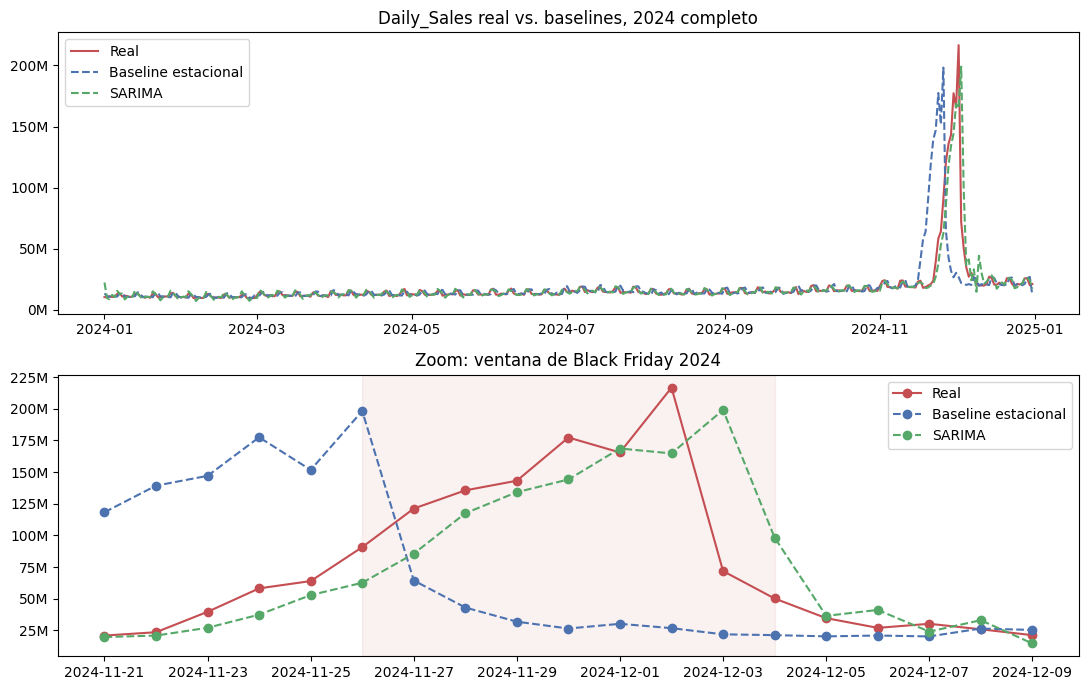

In [17]:
# Celda: gráfico comparativo, real vs. los dos baselines (2024)

test_plot = daily.loc[es_2024, ["Purchase_Date", "Daily_Sales", "Baseline_Estacional", "Baseline_SARIMA", "En_Ventana_BF"]]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Panel 1: todo 2024
ax = axes[0]
ax.plot(test_plot["Purchase_Date"], test_plot["Daily_Sales"], label="Real", color=PALETA[3], linewidth=1.5)
ax.plot(test_plot["Purchase_Date"], test_plot["Baseline_Estacional"], label="Baseline estacional", color=PALETA[0], linestyle="--")
ax.plot(test_plot["Purchase_Date"], test_plot["Baseline_SARIMA"], label="SARIMA", color=PALETA[2], linestyle="--")
ax.set_title("Daily_Sales real vs. baselines, 2024 completo")
millones(ax)
ax.legend()

# Panel 2: zoom en la ventana de Black Friday
ventana = test_plot[test_plot["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom = test_plot[
    (test_plot["Purchase_Date"] >= ventana["Purchase_Date"].min() - margen) &
    (test_plot["Purchase_Date"] <= ventana["Purchase_Date"].max() + margen)
]

ax = axes[1]
ax.plot(zoom["Purchase_Date"], zoom["Daily_Sales"], label="Real", color=PALETA[3], linewidth=1.5, marker="o")
ax.plot(zoom["Purchase_Date"], zoom["Baseline_Estacional"], label="Baseline estacional", color=PALETA[0], linestyle="--", marker="o")
ax.plot(zoom["Purchase_Date"], zoom["Baseline_SARIMA"], label="SARIMA", color=PALETA[2], linestyle="--", marker="o")
ax.axvspan(ventana["Purchase_Date"].min(), ventana["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
ax.set_title("Zoom: ventana de Black Friday 2024")
millones(ax)
ax.legend()

plt.tight_layout()
plt.show()

### Cierre del punto b)

El gráfico compara la venta real de 2024 contra los dos baselines. A simple vista el baseline
estacional replica razonablemente el nivel general pero no anticipa bien el pico de Black Friday
(la fecha de BF se mueve entre años, así que "el mismo día un año atrás" no queda alineado con el
evento). El SARIMA sigue mejor la forma de la serie porque se ajusta a la estacionalidad semanal,
aunque tampoco ve nada del evento BF en sí, porque no usa ninguna variable de calendario ni de
cercanía al evento. Las métricas de ambos se retoman y comparan con los modelos supervisados en el
punto e).

## c) Partición y estrategia de validación

Usamos **2024 como test final**, que no se toca hasta el punto e). Para entrenar y elegir
hiperparámetros usamos **2022 y 2023**.

Dentro de ese train, en vez de un único holdout o un k-fold aleatorio, usamos `TimeSeriesSplit`
(validación cruzada temporal, con ventana expansiva): cada fold entrena con todo lo anterior a una
fecha de corte y valida con el tramo siguiente, respetando el orden cronológico. Un k-fold
aleatorio mezclaría pasado y futuro dentro de la selección de modelos, lo que daría una estimación
del error optimista y poco realista (el modelo "vería" datos del futuro para predecir el pasado).

También evaluamos una ventana móvil de tamaño fijo (en vez de expansiva) y la descartamos: no hay
indicios de que el negocio haya cambiado de régimen ni de que la historia vieja moleste, así que
no hace falta olvidarla.

Usamos `n_splits=6`. La celda siguiente muestra los folds resultantes: como el lag de 365 días
recién tiene historia real completa a partir de 2023, los primeros folds (que tocan 2022) todavía
tienen `NaN` en esa columna, algo esperable dado cómo se construyó la variable, y que se trata
explícitamente en el punto d).

In [18]:
# Celda: partición train+validación (2022-2023) vs. test final (2024)

es_2024 = daily["Purchase_Date"].dt.year == 2024

train_val = daily.loc[~es_2024].sort_values("Purchase_Date").reset_index(drop=True)
test = daily.loc[es_2024].sort_values("Purchase_Date").reset_index(drop=True)

print(f"train+validación: {train_val['Purchase_Date'].min().date()} a {train_val['Purchase_Date'].max().date()} ({len(train_val)} filas)")
print(f"test (holdout final, no se toca hasta el punto e): {test['Purchase_Date'].min().date()} a {test['Purchase_Date'].max().date()} ({len(test)} filas)")

# n_splits=5: cada fold de validación queda con ~120 días, un balance razonable entre
# tener varios folds (estimación más robusta del error) y que cada uno cubra un tramo
# largo del año (para no evaluar solo sobre una estación particular).
tscv = TimeSeriesSplit(n_splits=6)

# Chequeo rápido de que los folds respetan el orden temporal y no se solapan
for i, (tr_idx, val_idx) in enumerate(tscv.split(train_val), 1):
    fechas_tr = train_val.loc[tr_idx, "Purchase_Date"]
    fechas_val = train_val.loc[val_idx, "Purchase_Date"]
    print(f"Fold {i}: train hasta {fechas_tr.max().date()} ({len(tr_idx)} filas)"
          f"  |  val {fechas_val.min().date()} a {fechas_val.max().date()} ({len(val_idx)} filas)"
          f"  |  NaN en Lag365 (val): {train_val.loc[val_idx, 'Daily_Sales_Lag365'].isna().sum()}")

train+validación: 2022-01-01 a 2023-12-31 (730 filas)
test (holdout final, no se toca hasta el punto e): 2024-01-01 a 2024-12-31 (366 filas)
Fold 1: train hasta 2022-04-16 (106 filas)  |  val 2022-04-17 a 2022-07-29 (104 filas)  |  NaN en Lag365 (val): 104
Fold 2: train hasta 2022-07-29 (210 filas)  |  val 2022-07-30 a 2022-11-10 (104 filas)  |  NaN en Lag365 (val): 104
Fold 3: train hasta 2022-11-10 (314 filas)  |  val 2022-11-11 a 2023-02-22 (104 filas)  |  NaN en Lag365 (val): 51
Fold 4: train hasta 2023-02-22 (418 filas)  |  val 2023-02-23 a 2023-06-06 (104 filas)  |  NaN en Lag365 (val): 0
Fold 5: train hasta 2023-06-06 (522 filas)  |  val 2023-06-07 a 2023-09-18 (104 filas)  |  NaN en Lag365 (val): 0
Fold 6: train hasta 2023-09-18 (626 filas)  |  val 2023-09-19 a 2023-12-31 (104 filas)  |  NaN en Lag365 (val): 0


## d) Modelos supervisados

Entrenamos dos modelos de familias distintas:
- **Ridge**: regresión lineal con regularización L2 (penaliza coeficientes grandes). Es
  interpretable y rápido, y sirve de punto de comparación directo con el baseline estacional.
- **LightGBM**: un ensamble de árboles con boosting. A diferencia de un modelo lineal, puede
  capturar no linealidades e interacciones entre variables (por ejemplo, entre `En_Ventana_BF` y
  el día de la semana) sin que haya que especificarlas a mano.

Se evaluaron como alternativas ElasticNet, XGBoost, Random Forest y SVR, pero se optó por esta
combinación por ser la comparación más informativa: lineal regularizado contra no lineal, que
cubre bien el espectro de complejidad sin duplicar familias parecidas.

### El problema del NaN en Lag365

Como vimos en el punto a), la columna `Daily_Sales_Lag365` (y las demás autorregresivas) tienen
`NaN` en las filas sin suficiente historia. LightGBM tolera `NaN` de forma nativa (decide en cada
split si mandar esas filas para un lado o el otro del árbol), pero Ridge no admite `NaN` en
absoluto.

Para poder comparar ambos modelos de forma justa, y para medir cuánto importa la forma de tratar
el `NaN`, corrimos tres configuraciones:
1. **LightGBM con NaN nativo**: sin tocar nada.
2. **LightGBM con flag + imputación**: se agrega una columna `*_Disponible` (1 si el dato existía,
   0 si se imputó) y se rellena el `NaN` con la mediana de train, para poder comparar contra la
   corrida 1 y aislar el efecto de tratar el NaN.
3. **Ridge con flag + imputación**: mismo tratamiento que 2, porque Ridge no tiene alternativa.

La mediana usada para imputar se calcula solo con datos de train, nunca con test, para no filtrar
información del período de evaluación hacia el entrenamiento.

### Armado de las variables predictoras

De las 42 columnas de `daily`, se excluyen de las variables predictoras: la fecha y el target, las
variables de actividad del propio día (`Transactions`, `Clientes_Unicos`, `Productos_Unicos`,
`Prop_Online`/`Store`, `Prop_Categoria_Top`, `Categorias_Distintas`), porque son descriptivas del
punto a) pero no se conocen de antemano el día que se quiere predecir, y las predicciones de los
baselines del punto b) (`Baseline_Estacional`, `Baseline_SARIMA`, `CPI_Index_Lag365`), que son
resultados, no insumos.

In [19]:
# Celda: armado de X, y y las dos versiones del dataset (NaN nativo vs. flag+imputación)
COLUMNAS_EXCLUIR = [
    "Purchase_Date", "Daily_Sales",              # target y su llave temporal
    "Transactions", "Clientes_Unicos", "Productos_Unicos",
    "Prop_Online", "Prop_Store", "Prop_Categoria_Top", "Categorias_Distintas",  # mismo día, leakage
    "Baseline_Estacional", "Baseline_SARIMA", "CPI_Index_Lag365",              # benchmarks del punto b
]
FEATURES = [c for c in daily.columns if c not in COLUMNAS_EXCLUIR]
print(f"{len(FEATURES)} features:", FEATURES)

X_train_val = train_val[FEATURES].copy()
y_train_val = train_val["Daily_Sales"].copy()
X_test = test[FEATURES].copy()
y_test = test["Daily_Sales"].copy()

# --- Versión con NaN nativo (para boosting, opción 4) ---
X_train_val_nan = X_train_val.copy()
X_test_nan = X_test.copy()

# --- Versión con flag + imputación neutra (para Ridge y para el boosting de comparación, opción 5) ---
COLUMNAS_CON_HISTORIA_INCOMPLETA = [c for c in FEATURES if X_train_val[c].isna().any()]
print("Columnas con NaN a tratar:", COLUMNAS_CON_HISTORIA_INCOMPLETA)

X_train_val_imp = X_train_val.copy()
X_test_imp = X_test.copy()
for col in COLUMNAS_CON_HISTORIA_INCOMPLETA:
    mediana_train = X_train_val[col].median()  # mediana calculada SOLO con train, nunca con test
    X_train_val_imp[f"{col}_Disponible"] = X_train_val[col].notna().astype(int)
    X_test_imp[f"{col}_Disponible"] = X_test[col].notna().astype(int)
    X_train_val_imp[col] = X_train_val[col].fillna(mediana_train)
    X_test_imp[col] = X_test[col].fillna(mediana_train)

33 features: ['Dow', 'Month', 'Quarter', 'Is_Weekend', 'Dow_Sin', 'Dow_Cos', 'Month_Sin', 'Month_Cos', 'Days_To_Black_Friday', 'Dias_Abs_BF', 'En_Ventana_BF', 'CPI_Index', 'Monthly_Inflation_Rate', 'Consumer_Confidence_Index', 'Retail_Activity_Index', 'Daily_Sales_Lag1', 'Daily_Sales_Lag7', 'Daily_Sales_Lag14', 'Daily_Sales_Lag28', 'Daily_Sales_Lag365', 'Daily_Sales_Media7', 'Daily_Sales_Desvio7', 'Daily_Sales_Media28', 'Daily_Sales_Desvio28', 'Transactions_Lag1', 'Transactions_Lag7', 'Transactions_Lag14', 'Transactions_Lag28', 'Transactions_Lag365', 'Transactions_Media7', 'Transactions_Desvio7', 'Transactions_Media28', 'Transactions_Desvio28']
Columnas con NaN a tratar: ['Daily_Sales_Lag1', 'Daily_Sales_Lag7', 'Daily_Sales_Lag14', 'Daily_Sales_Lag28', 'Daily_Sales_Lag365', 'Daily_Sales_Media7', 'Daily_Sales_Desvio7', 'Daily_Sales_Media28', 'Daily_Sales_Desvio28', 'Transactions_Lag1', 'Transactions_Lag7', 'Transactions_Lag14', 'Transactions_Lag28', 'Transactions_Lag365', 'Transactions_

### Búsqueda de hiperparámetros

Para las tres corridas usamos `GridSearchCV` con `cv=tscv` (el `TimeSeriesSplit` del punto c) y
`scoring="neg_root_mean_squared_error"`, así la selección de hiperparámetros respeta el orden
temporal igual que la validación.

En LightGBM exploramos cantidad de árboles (`n_estimators`), profundidad (`max_depth`) y
velocidad de aprendizaje (`learning_rate`). En Ridge, la fuerza de la regularización (`alpha`).
Antes de Ridge hace falta escalar las variables con `StandardScaler`, porque penaliza los
coeficientes según su magnitud: sin escalar, una variable en millones (como `Daily_Sales_Lag1`)
pesaría artificialmente más que una en unidades chicas.

In [20]:
# Celda: corrida 1, LightGBM con NaN nativo (opción 4)
grid_lgbm = {
    "n_estimators": [300 ,500, 800, 1200],
    "max_depth": [2, 3, 5, -1],
    "learning_rate": [ 0.1, 0.15, 0.2, 0.25],
}

lgbm_nan = GridSearchCV(
    LGBMRegressor(random_state=42),
    grid_lgbm, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lgbm_nan.fit(X_train_val_nan, y_train_val)
print("Mejor combinación (NaN nativo):", lgbm_nan.best_params_)
print("RMSE promedio en CV:", -lgbm_nan.best_score_)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000183 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4739
[LightGBM] [Info] Number of data points in the train set: 730, number of used features: 32
[LightGBM] [Info] Start training from score 15222860.575342
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [21]:
# Celda: corrida 2, LightGBM con flag+imputación (opción 5), mismo grid, para comparar contra la corrida 1
lgbm_imp = GridSearchCV(
    LGBMRegressor(random_state=42),
    grid_lgbm, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lgbm_imp.fit(X_train_val_imp, y_train_val)
print("Mejor combinación (flag+imputación):", lgbm_imp.best_params_)
print("RMSE promedio en CV:", -lgbm_imp.best_score_)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000228 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5037
[LightGBM] [Info] Number of data points in the train set: 730, number of used features: 40
[LightGBM] [Info] Start training from score 15222860.575342
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [22]:
# Celda: corrida 3, Ridge con flag+imputación (opción 5)

# StandardScaler es necesario acá porque Ridge penaliza los coeficientes según su
# magnitud: sin escalar, una variable en millones (Daily_Sales_Lag1) pesaría distinto
# que una en el rango 0-1 (Is_Weekend) solo por la escala, no por su importancia real.
# LightGBM no lo necesita porque decide splits comparando valores dentro de cada
# variable, no entre variables.
grid_ridge = {"ridge__alpha": [0.001, 0.005, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]}

ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge(random_state=42)),
    grid_ridge, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge.fit(X_train_val_imp, y_train_val)
print("Mejor alpha:", ridge.best_params_)
print("RMSE promedio en CV:", -ridge.best_score_)

Mejor alpha: {'ridge__alpha': 10.0}
RMSE promedio en CV: 6555710.278876762


### Resultados de las tres corridas

El mejor `alpha` de Ridge fue 10 (ver salida de la celda anterior), con un RMSE promedio en la
validación cruzada de 6,56 millones. Antes de comparar los tres, vale aclarar una decisión sobre
la cantidad de folds: se probó también con menos folds y el resultado cambiaba bastante, porque
los folds que contienen a Black Friday concentran la enorme mayoría del error (como se ve en la
tabla siguiente, el Fold 3 es un orden de magnitud peor que el resto) y son pocos folds los que
tienen un BF adentro. Con `n_splits=6` esos folds pesan menos en el promedio general que con menos
folds, y el resultado quedó más estable. Se decidió no seguir ajustando esto después de fijar los
6 folds.

La siguiente tabla muestra el RMSE de cada modelo en cada uno de los 6 folds:

In [23]:
# Celda: RMSE por fold de los tres modelos ganadores (en millones)
def rmse_por_fold(gs):
    i = gs.best_index_
    return {f"Fold {k+1}": -gs.cv_results_[f"split{k}_test_score"][i] / 1e6 for k in range(6)}

pd.DataFrame({
    "LGBM NaN nativo": rmse_por_fold(lgbm_nan),
    "LGBM flag+imputación": rmse_por_fold(lgbm_imp),
    "Ridge flag+imputación": rmse_por_fold(ridge),
}).round(2)

,LGBM NaN nativo,LGBM flag+imputación,Ridge flag+imputación
Fold 1,1.28,1.33,0.78
Fold 2,1.26,1.31,0.70
Fold 3,27.98,27.65,25.04
Fold 4,0.60,0.82,0.93
Fold 5,1.32,2.25,1.15
Fold 6,8.92,12.01,10.74


In [24]:
# Celda: RMSE de referencia sobre los mismos folds (reglas triviales, en millones)
def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

filas = []
for i, (tr, val) in enumerate(tscv.split(train_val), 1):
    v = train_val.iloc[val]
    fila = {"Fold": i}
    for nombre, col in [("Igual que ayer (Lag1)", "Daily_Sales_Lag1"),
                        ("Igual que hace 7 días (Lag7)", "Daily_Sales_Lag7"),
                        ("Baseline estacional", "Baseline_Estacional")]:
        ok = v[col].notna()
        fila[nombre] = rmse(v.loc[ok, "Daily_Sales"], v.loc[ok, col]) / 1e6 if ok.any() else np.nan
    filas.append(fila)

pd.DataFrame(filas).set_index("Fold").round(2)

,Igual que ayer (Lag1),Igual que hace 7 días (Lag7),Baseline estacional
Fold,,,
1,1.68,0.69,NaN
2,2.02,1.01,NaN
3,12.41,35.04,1.44
4,1.63,0.68,1.66
5,2.02,0.88,1.95
6,13.80,38.33,13.74


La tabla de arriba compara contra dos reglas triviales ("la venta de ayer", "la venta de hace 7
días") y contra el baseline estacional del punto b), calculados sobre los mismos folds. El Fold 3
es el más difícil para todos, real o trivial: ahí cae un Black Friday (el de 2022) que el modelo
entrena sin haber visto ningún otro antes, así que hasta la regla más simple se equivoca mucho
(35,04 millones de RMSE para "hace 7 días"). Fuera de ese fold, los tres modelos superan
claramente a las reglas triviales.

## e) Evaluación

Elegimos tres métricas, cada una mirando el error desde un ángulo distinto:
- **RMSE** (raíz del error cuadrático medio): penaliza fuerte los errores grandes, relevante
  porque Black Friday genera picos que un buen modelo debería anticipar.
- **MAE** (error absoluto medio): más robusta a outliers, da una noción del error "típico" de un
  día cualquiera, en las mismas unidades que `Daily_Sales`.
- **sMAPE** (error porcentual absoluto simétrico): como la venta diaria varía mucho entre
  temporada baja y Black Friday, esta métrica relativa evita que el MAPE tradicional (que también
  existe, pero se vuelve inestable con valores chicos en el denominador) explote.

Con los modelos ya entrenados (usando todo 2022-2023, la configuración ganadora de cada
`GridSearchCV`), predecimos sobre 2024 y calculamos las tres métricas.

In [25]:
# Celda: predicciones sobre test 2024 y métricas
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Chequeo de que los objetos en memoria son los de 6 folds
print("Folds usados:", lgbm_nan.n_splits_, lgbm_imp.n_splits_, ridge.n_splits_)

pred_test = pd.DataFrame({
    "Purchase_Date": test["Purchase_Date"].values,
    "Real": y_test.values,
    "En_Ventana_BF": test["En_Ventana_BF"].values,
})
pred_test["LGBM_NaN"] = lgbm_nan.predict(X_test_nan)
pred_test["LGBM_Imp"] = lgbm_imp.predict(X_test_imp)
pred_test["Ridge"] = ridge.predict(X_test_imp)
pred_test["Baseline_Estacional"] = test["Baseline_Estacional"].values
pred_test["Baseline_SARIMA"] = test["Baseline_SARIMA"].values
pred_test["Lag7"] = test["Daily_Sales_Lag7"].values

modelos = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_Estacional", "Baseline_SARIMA", "Lag7"]
print("NaN en predicciones (se espera 0):", pred_test[modelos].isna().sum().sum())

def metricas(real, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "MAE": mean_absolute_error(real, pred),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(real - pred) / (np.abs(real) + np.abs(pred))),
    }

tabla = pd.DataFrame({m: metricas(pred_test["Real"], pred_test[m]) for m in modelos}).T
tabla["RMSE"] /= 1e6
tabla["MAE"] /= 1e6
tabla = tabla.rename(columns={"RMSE": "RMSE (M)", "MAE": "MAE (M)"}).sort_values("RMSE (M)").round(2)
tabla

Folds usados: 6 6 6
NaN en predicciones (se espera 0): 0


,RMSE (M),MAE (M),sMAPE (%)
LGBM_NaN,5.94,2.07,11.14
Ridge,6.85,2.07,9.44
LGBM_Imp,7.50,2.83,15.97
Baseline_SARIMA,8.63,2.24,8.66
Baseline_Estacional,22.39,5.92,15.06
Lag7,24.15,5.76,12.00


LightGBM con NaN nativo tiene el mejor RMSE y MAE (5,94M y 2,07M), Ridge queda muy cerca en MAE
(también 2,07M) y tiene el mejor sMAPE (9,44%). LightGBM con imputación queda peor que su versión
con NaN nativo en las tres métricas: tratar el NaN explícitamente no ayudó acá. Los dos modelos
supervisados le ganan claramente a los dos baselines del punto b) y a las reglas triviales, lo que
confirma que valió la pena construir variables autorregresivas y no quedarse con una regla simple.

### Observado vs. predicho

Graficamos las predicciones de los cuatro modelos contra la venta real, para todo 2024 y con zoom
en la ventana de Black Friday.

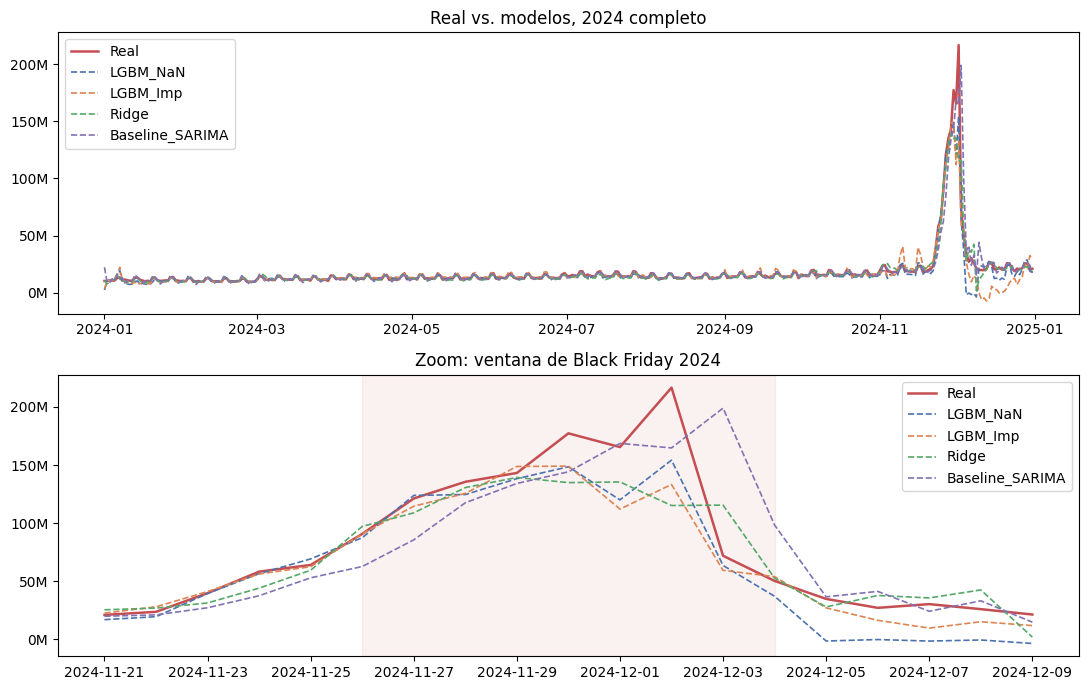

In [26]:
# Celda: observado vs. predicho en 2024 (año completo y zoom en la ventana de Black Friday)
import matplotlib.pyplot as plt

colores = {"LGBM_NaN": PALETA[0], "LGBM_Imp": PALETA[1], "Ridge": PALETA[2], "Baseline_SARIMA":PALETA[4]}

ventana = pred_test[pred_test["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom = pred_test[
    (pred_test["Purchase_Date"] >= ventana["Purchase_Date"].min() - margen) &
    (pred_test["Purchase_Date"] <= ventana["Purchase_Date"].max() + margen)
]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, datos, titulo in [(axes[0], pred_test, "Real vs. modelos, 2024 completo"),
                          (axes[1], zoom, "Zoom: ventana de Black Friday 2024")]:
    ax.plot(datos["Purchase_Date"], datos["Real"], label="Real", color=PALETA[3], linewidth=1.8)
    for m, c in colores.items():
        ax.plot(datos["Purchase_Date"], datos[m], label=m, color=c, linestyle="--", linewidth=1.2)
    ax.set_title(titulo)
    millones(ax)
    ax.legend()
axes[1].axvspan(ventana["Purchase_Date"].min(), ventana["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
plt.tight_layout()
plt.show()

En el año completo las cuatro curvas siguen de cerca a la real. El zoom en la ventana de BF
muestra que todas subestiman el pico en algún grado (se retoma con números en el punto f).

### Dispersión y sesgo de los residuos

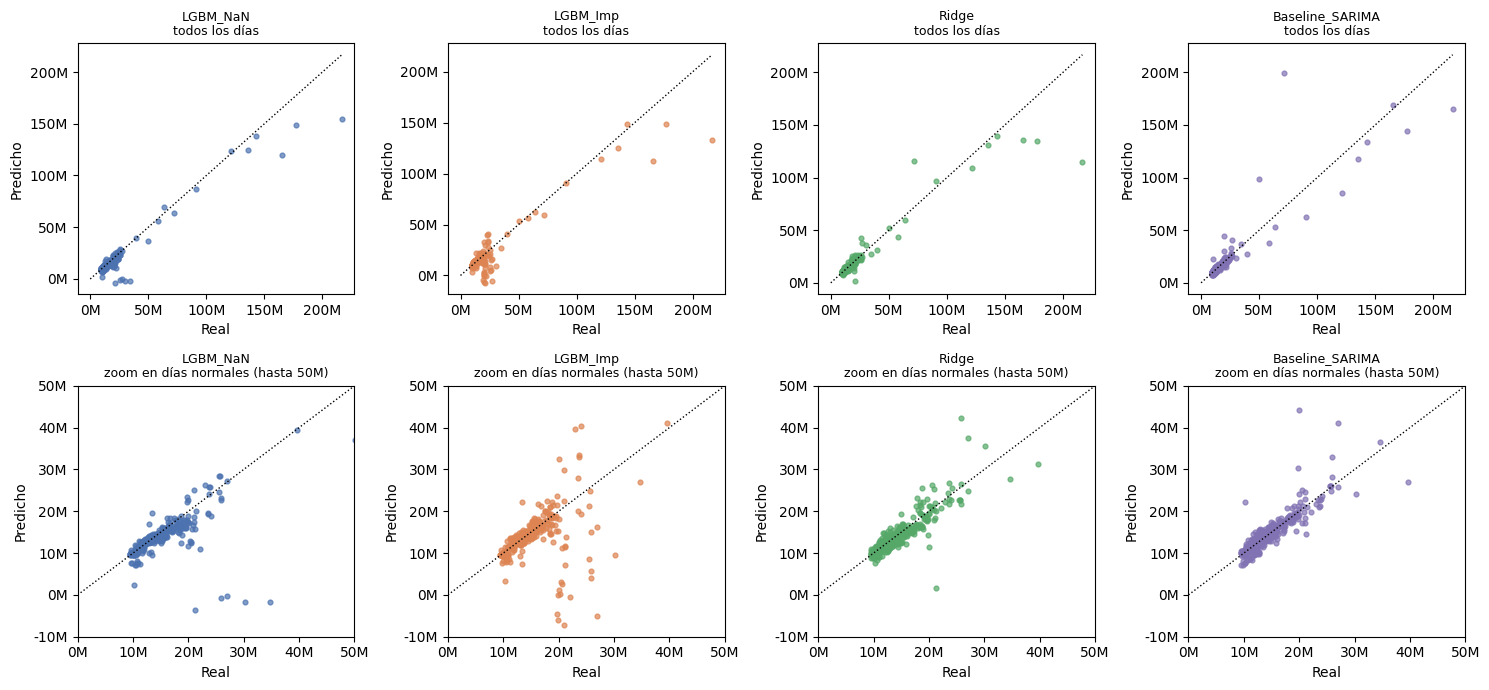

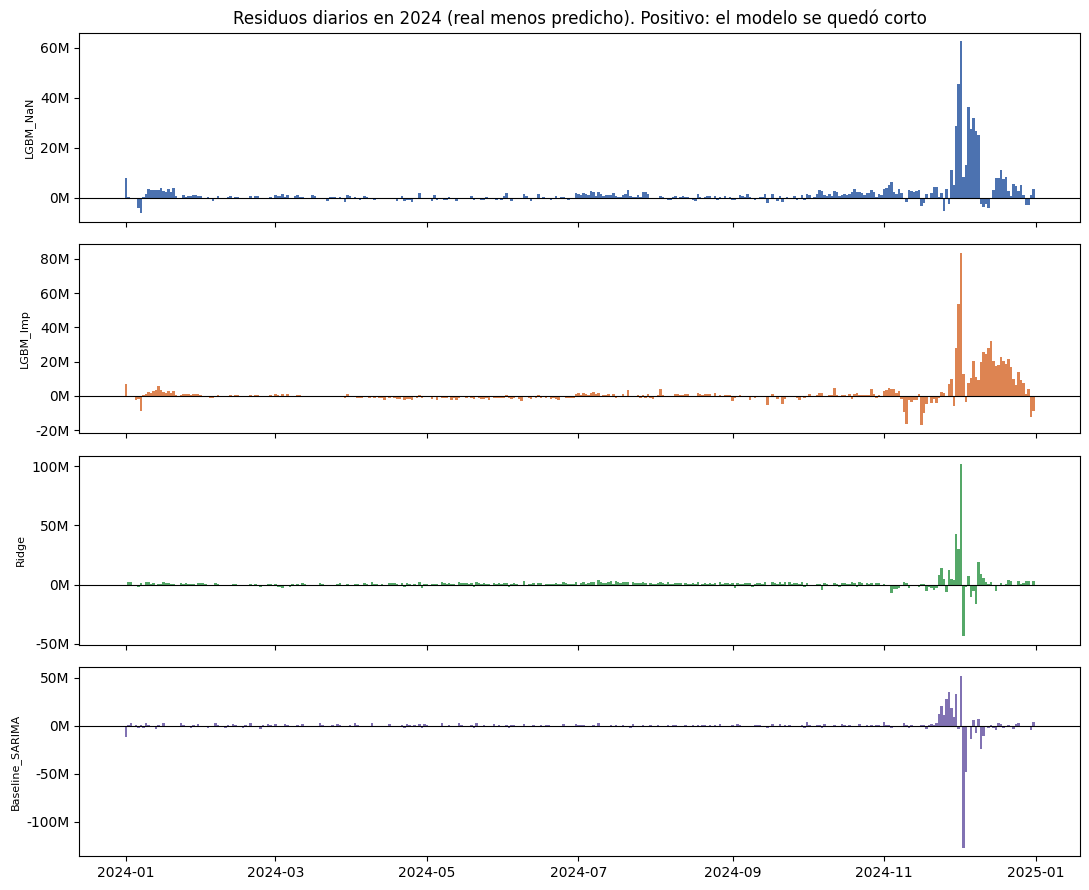

,Sesgo medio (M),Mediana del residuo (M),Días en que se quedó corto (%)
LGBM_NaN,1.43,0.32,59.02
LGBM_Imp,1.28,-0.04,48.09
Ridge,0.82,0.69,67.21
Baseline_SARIMA,-0.05,-0.05,47.81


In [27]:
# Celda: dispersión observado vs. predicho y residuos diarios
modelos_4 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA"]
COL = {"LGBM_NaN": PALETA[0], "LGBM_Imp": PALETA[1], "Ridge": PALETA[2], "Baseline_SARIMA": PALETA[4],
       "Baseline_Estacional": PALETA[5], "Lag7": PALETA[6]}
pred_test["Mes"] = pred_test["Purchase_Date"].dt.month
for m in modelos_4:
    pred_test[f"res_{m}"] = pred_test["Real"] - pred_test[m]

# Arriba: todos los días. Abajo: zoom en días normales. La línea punteada es la predicción perfecta.
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, m in enumerate(modelos_4):
    for i, titulo in enumerate(["todos los días", "zoom en días normales (hasta 50M)"]):
        ax = axes[i, j]
        ax.scatter(pred_test["Real"], pred_test[m], s=12, color=COL[m], alpha=0.7)
        tope = pred_test["Real"].max() if i == 0 else 50e6
        ax.plot([0, tope], [0, tope], color="black", linewidth=1, linestyle=":")
        if i == 1:
            ax.set_xlim(0, 50e6); ax.set_ylim(-10e6, 50e6)
        ax.set_title(f"{m}\n{titulo}", fontsize=9)
        ax.set_xlabel("Real"); ax.set_ylabel("Predicho")
        millones(ax, "x"); millones(ax, "y")
plt.tight_layout(); plt.show()

# Residuos diarios
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, m in zip(axes, modelos_4):
    ax.bar(pred_test["Purchase_Date"], pred_test[f"res_{m}"], color=COL[m], width=1.0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(m, fontsize=8)
    millones(ax)
axes[0].set_title("Residuos diarios en 2024 (real menos predicho). Positivo: el modelo se quedó corto")
plt.tight_layout(); plt.show()

# ¿Se equivocan sistemáticamente para un lado?
res = pred_test[[f"res_{m}" for m in modelos_4]].copy()
res.columns = modelos_4
pd.DataFrame({
    "Sesgo medio (M)": res.mean() / 1e6,
    "Mediana del residuo (M)": res.median() / 1e6,
    "Días en que se quedó corto (%)": (res > 0).mean() * 100,
}).round(2)

Los cuatro modelos tienen sesgo positivo (predicen, en promedio, por debajo de lo real): entre
0,82M (Ridge) y 1,43M (LGBM_NaN) de sesgo medio, salvo el SARIMA que está casi sin sesgo (-0,05M).
Coherente con eso, Ridge se queda corto el 67,21% de los días, más que los demás. Este sesgo se
entiende mejor mirando dónde se concentra el error (siguiente celda) y qué pasa específicamente en
Black Friday (punto f).

### Dónde se concentra el error

,% del error cuadrático en sus 10 peores días,5 peores días
Modelo,,
LGBM_NaN,89.1,"02-Dec, 01-Dec, 05-Dec, 07-Dec, 30-Nov"
LGBM_Imp,73.3,"02-Dec, 01-Dec, 14-Dec, 13-Dec, 30-Nov"
Ridge,93.8,"02-Dec, 03-Dec, 30-Nov, 01-Dec, 09-Dec"
Baseline_SARIMA,95.0,"03-Dec, 02-Dec, 04-Dec, 27-Nov, 30-Nov"


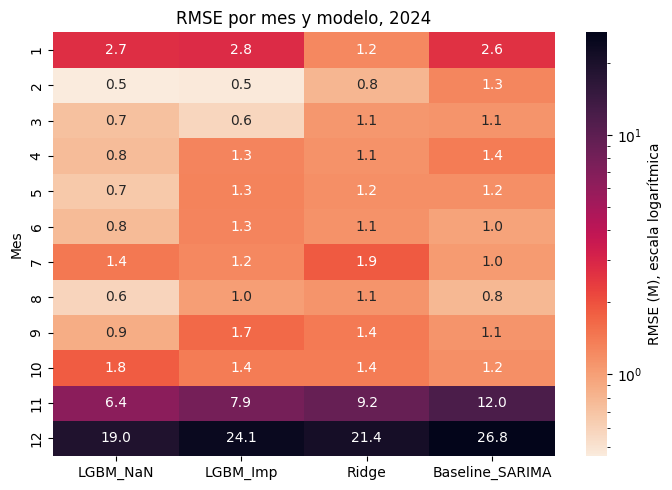

In [28]:
# Celda: dónde se concentra el error
from matplotlib.colors import LogNorm

filas = []
for m in modelos_4:
    e2 = pred_test[f"res_{m}"] ** 2
    filas.append({
        "Modelo": m,
        "% del error cuadrático en sus 10 peores días": round(100 * e2.nlargest(10).sum() / e2.sum(), 1),
        "5 peores días": ", ".join(pred_test.loc[e2.nlargest(5).index, "Purchase_Date"].dt.strftime("%d-%b")),
    })
display(pd.DataFrame(filas).set_index("Modelo"))

rmse_mes = pd.DataFrame({
    m: pred_test.groupby("Mes")[f"res_{m}"].apply(lambda s: np.sqrt((s ** 2).mean())) for m in modelos_4
}) / 1e6

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(rmse_mes, annot=True, fmt=".1f", cmap="rocket_r", norm=LogNorm(),
            cbar_kws={"label": "RMSE (M), escala logarítmica"}, ax=ax)
ax.set_title("RMSE por mes y modelo, 2024")
plt.tight_layout(); plt.show()

Muy poca cantidad de días explica casi todo el error cuadrático: los 10 peores días concentran
entre 73,3% (LGBM_Imp) y 95,0% (SARIMA) del error total. Esta concentración alta no es
necesariamente mala: quiere decir que en el resto del año los modelos son muy precisos, y que el
desafío real está en un puñado de fechas de fin de noviembre y principios de diciembre, todas
cerca de Black Friday (ver el listado de peores días de cada modelo arriba).

### Autocorrelación de los residuos

Si los residuos (real menos predicho) están correlacionados entre sí día a día, quiere decir que
al modelo se le está escapando un patrón sistemático que todavía podría explotar.

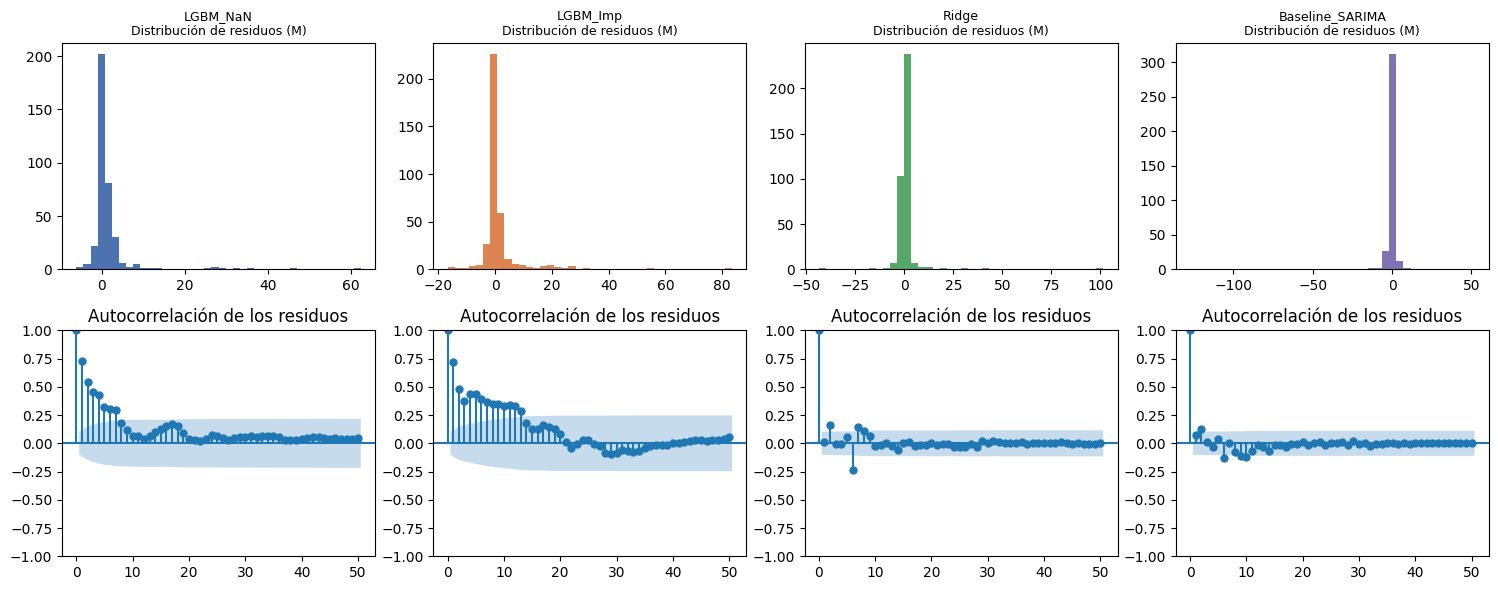

In [29]:
# Celda: distribución y autocorrelación de los residuos
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, m in enumerate(modelos_4):
    axes[0, j].hist(pred_test[f"res_{m}"] / 1e6, bins=40, color=COL[m])
    axes[0, j].set_title(f"{m}\nDistribución de residuos (M)", fontsize=9)
    plot_acf(pred_test[f"res_{m}"], lags=50, ax=axes[1, j], title="Autocorrelación de los residuos")
plt.tight_layout(); plt.show()

Los dos modelos de LightGBM muestran autocorrelación alta en los primeros lags (rachas de
residuos del mismo signo seguidos), mientras que Ridge y el SARIMA quedan dentro de la banda de
ruido esperable. Es un indicio de que LightGBM tiene un sesgo que persiste varios días seguidos,
probablemente ligado al comportamiento después del pico de Black Friday (se retoma en el punto f).

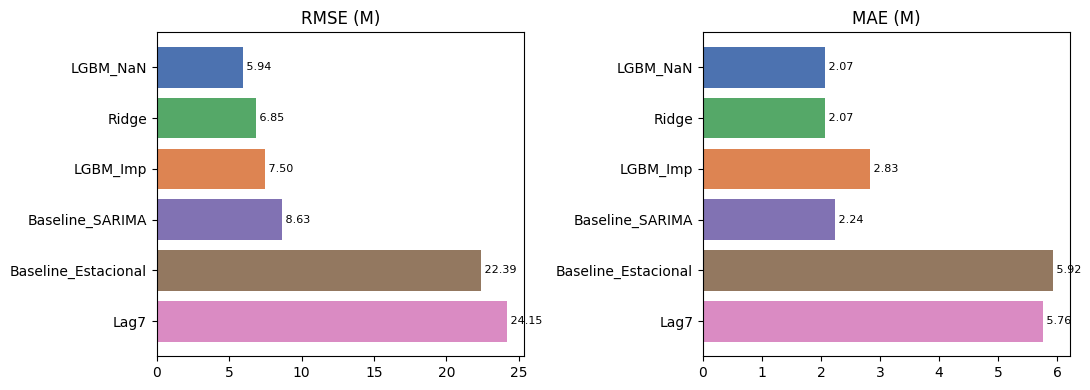

In [30]:
# Celda: modelos contra referencias, RMSE y MAE
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orden = tabla.index.tolist()
for ax, col in zip(axes, ["RMSE (M)", "MAE (M)"]):
    ax.barh(orden, tabla[col], color=[COL[m] for m in orden])
    ax.invert_yaxis()
    ax.set_title(col)
    for y, v in enumerate(tabla[col]):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

El gráfico resume el ranking de RMSE y MAE ya visto en la tabla de arriba: LightGBM NaN nativo
primero, Ridge segundo y muy cerca, LightGBM con imputación y SARIMA detrás, y los dos baselines
simples muy por debajo de los cuatro modelos anteriores.

## f) Black Friday

Black Friday es el evento de mayor interés de negocio y el más difícil de predecir: un modelo
puede tener buen desempeño promedio y aun así fallar justo donde más importa. Para analizarlo por
separado dividimos el año en tres zonas:
- **Ventana BF**: los 9 días que van del 26 de noviembre al 4 de diciembre de 2024
  (`Days_To_Black_Friday` entre -3 y +5), definidos por la bandera `En_Ventana_BF` ya calculada en
  el TP2.
- **Después de la ventana**: del 5 al 31 de diciembre (27 días). Se separa del resto del año a
  propósito, porque ahí es donde se concentran los residuos con racha que vimos en el punto e);
  mezclarla con el resto del año escondería ese problema dentro del promedio general.
- **Resto del año**: los 330 días restantes.

Recalculamos RMSE y MAE del punto e) pero separados por zona, y además un RMSE relativo (como
porcentaje de la venta media de cada zona), porque las tres zonas tienen niveles de venta muy
distintos y comparar el error en valores absolutos entre ellas sería engañoso.

In [31]:
# Celda: desempeño por zona (ventana de BF, después de la ventana y resto del año)
pred_test["Dias_BF"] = test["Days_To_Black_Friday"].values
pred_test["Zona"] = np.select(
    [pred_test["En_Ventana_BF"] == 1, pred_test["Dias_BF"] > 5],
    ["Ventana BF", "Después de la ventana"],
    default="Resto del año",
)
print(pred_test["Zona"].value_counts())

modelos_6 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA", "Baseline_Estacional", "Lag7"]
zonas = ["Ventana BF", "Después de la ventana", "Resto del año"]

def por_zona(f):
    filas = {"Global": {m: f(pred_test["Real"], pred_test[m]) for m in modelos_6}}
    for z in zonas:
        g = pred_test[pred_test["Zona"] == z]
        filas[z] = {m: f(g["Real"], g[m]) for m in modelos_6}
    return pd.DataFrame(filas)

rmse = lambda r, p: np.sqrt(np.mean((r - p) ** 2)) / 1e6
mae = lambda r, p: np.mean(np.abs(r - p)) / 1e6

medias = {"Global": pred_test["Real"].mean(),
          **{z: pred_test.loc[pred_test["Zona"] == z, "Real"].mean() for z in zonas}}
print("Venta media diaria real por zona (M)"); display((pd.Series(medias) / 1e6).round(1))
print("RMSE (M)"); display(por_zona(rmse).round(2))
print("MAE (M)"); display(por_zona(mae).round(2))
print("RMSE relativo (% de la venta media de la zona)")
display((por_zona(rmse) * 1e6 / pd.Series(medias) * 100).round(1))

Zona
Resto del año            330
Después de la ventana     27
Ventana BF                 9
Name: count, dtype: int64
Venta media diaria real por zona (M)


,0
Global,17.9
Ventana BF,130.2
Después de la ventana,23.1
Resto del año,14.4


RMSE (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,5.94,28.30,13.54,1.51
LGBM_Imp,7.50,34.90,17.29,2.17
Ridge,6.85,41.04,6.24,1.72
Baseline_SARIMA,8.63,52.46,6.50,2.01
Baseline_Estacional,22.39,113.62,4.94,14.21
Lag7,24.15,106.53,62.93,3.67


MAE (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,2.07,20.02,8.82,1.03
LGBM_Imp,2.83,22.62,15.51,1.26
Ridge,2.07,27.52,4.07,1.21
Baseline_SARIMA,2.24,39.37,4.02,1.08
Baseline_Estacional,5.92,102.56,3.33,3.50
Lag7,5.76,99.49,30.39,1.19


RMSE relativo (% de la venta media de la zona)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,33.3,21.7,58.7,10.5
LGBM_Imp,42.0,26.8,75.0,15.1
Ridge,38.4,31.5,27.1,11.9
Baseline_SARIMA,48.3,40.3,28.2,14.0
Baseline_Estacional,125.4,87.2,21.4,99.0
Lag7,135.3,81.8,273.0,25.6


En términos relativos (que es la comparación justa entre zonas), LightGBM NaN nativo es el mejor
dentro de la ventana de BF (21,7% de la venta media de la zona) y en el resto del año (10,5%),
pero el peor después de la ventana (58,7%), justo donde detectamos las rachas de residuos. Ridge
tiene el patrón inverso: peor en la ventana (31,5%) pero mejor después (27,1%). El baseline
estacional, que en el punto e) parecía claramente inferior, gana después de la ventana (21,4%)
porque no usa lags recientes contaminados por el pico; en cambio es el peor de todos en la ventana
misma (87,2%) y en el resto del año (99,0%), por la desalineación del BF entre años que ya se
discutió en el punto b).

### La dinámica dentro de la ventana de Black Friday

Miramos específicamente cómo cada modelo representa la forma del pico: si acierta el día, la
magnitud y el total vendido en la ventana.

In [32]:
# Celda: dinámica dentro de la ventana de BF (pico, momento del pico, forma y total vendido)
v = pred_test[pred_test["Zona"] == "Ventana BF"].reset_index(drop=True)
i_pico = v["Real"].idxmax()
pico_real = v.loc[i_pico, "Real"]
fecha_pico_real = v.loc[i_pico, "Purchase_Date"]
print(f"Pico real: {pico_real/1e6:.1f}M el {fecha_pico_real.strftime('%d-%b')}")

filas = []
for m in modelos_6:
    fecha_pico_m = v.loc[v[m].idxmax(), "Purchase_Date"]
    filas.append({
        "Modelo": m,
        "Predicho el día del pico (% del real)": 100 * v.loc[i_pico, m] / pico_real,
        "Día del pico predicho": fecha_pico_m.strftime("%d-%b"),
        "Desfase del pico (días)": (fecha_pico_m - fecha_pico_real).days,
        "Correlación con lo real": v["Real"].corr(v[m]),
        "Error en el total vendido (%)": 100 * (v[m].sum() / v["Real"].sum() - 1),
    })
pd.DataFrame(filas).set_index("Modelo").round(1)

Pico real: 216.7M el 02-Dec


,Predicho el día del pico (% del real),Día del pico predicho,Desfase del pico (días),Correlación con lo real,Error en el total vendido (%)
Modelo,,,,,
LGBM_NaN,71.2,02-Dec,0,0.9,-14.9
LGBM_Imp,61.5,30-Nov,-2,0.8,-15.8
Ridge,53.1,29-Nov,-3,0.7,-12.2
Baseline_SARIMA,76.0,03-Dec,1,0.4,0.2
Baseline_Estacional,12.3,26-Nov,-6,-0.3,-60.4
Lag7,29.5,04-Dec,2,-0.4,-61.1


El pico real fue de 216,7 millones el 2 de diciembre. LightGBM NaN nativo es el único modelo que
ubica el pico exactamente en el día correcto y el que tiene mayor correlación con la serie real
(0,9), aunque solo llega al 71,2% del valor del pico y subestima el total vendido de la ventana en
14,9%. El SARIMA acierta el día siguiente (un día de desfase) y con menor correlación (0,4), lo
que sugiere que su buen desempeño relativo en el total vendido viene más de una compensación de
errores que de representar bien la dinámica. Ridge pone el pico tres días antes de lo real (el
viernes de Black Friday, día 0): una suma lineal de variables no puede reproducir bien un pico que
llega corrido, tiene que "adelantarlo" hacia donde ya tiene señal fuerte (el día del evento en sí).

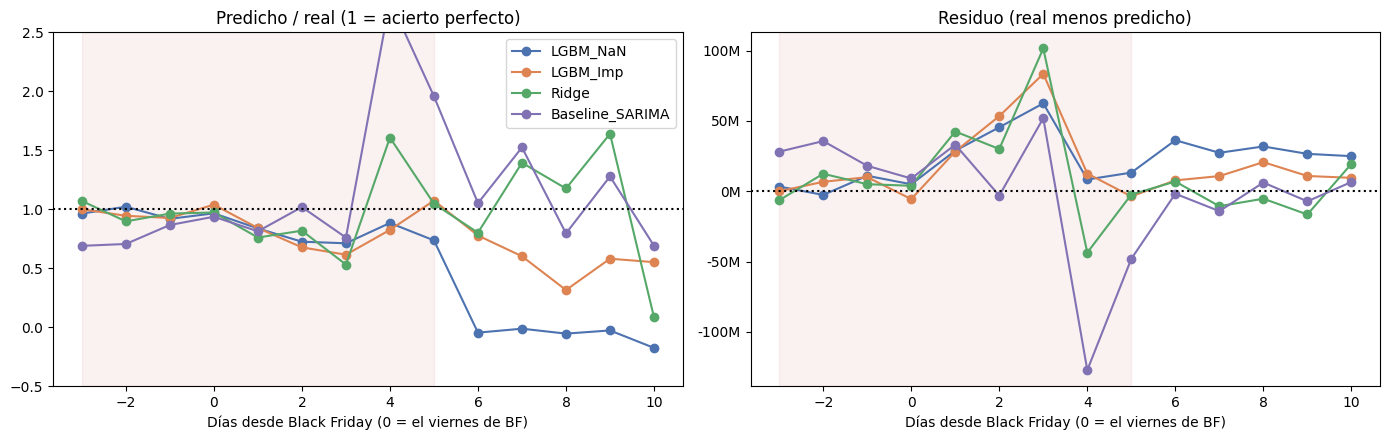

In [33]:
# Celda: día a día alrededor de Black Friday (predicho / real, y residuo)
zoom = pred_test[(pred_test["Dias_BF"] >= -3) & (pred_test["Dias_BF"] <= 10)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for m in modelos_4:
    axes[0].plot(zoom["Dias_BF"], zoom[m] / zoom["Real"], marker="o", label=m, color=COL[m])
    axes[1].plot(zoom["Dias_BF"], zoom[f"res_{m}"], marker="o", label=m, color=COL[m])
axes[0].axhline(1, color="black", linestyle=":")
axes[1].axhline(0, color="black", linestyle=":")
axes[0].set_ylim(-0.5, 2.5)
axes[0].set_title("Predicho / real (1 = acierto perfecto)")
axes[1].set_title("Residuo (real menos predicho)")
millones(axes[1])
for ax in axes:
    ax.axvspan(-3, 5, color=PALETA[3], alpha=0.08)
    ax.set_xlabel("Días desde Black Friday (0 = el viernes de BF)")
axes[0].legend()
plt.tight_layout(); plt.show()

El gráfico día a día confirma lo anterior: LightGBM sigue de cerca la forma del pico pero se queda
corto en la magnitud, Ridge llega tarde a reaccionar y adelanta el máximo, y los residuos de todos
los modelos se agrandan justo en el entorno del pico.

### Cierre del punto f)

No hay un modelo que gane en las tres zonas. LightGBM NaN nativo es el que mejor representa el
evento de Black Friday en sí, pero es el que peor se comporta en las semanas siguientes. Ridge y
el SARIMA son más conservadores durante el pico pero más confiables después. Conviene tener
presente que el test tiene un único Black Friday (9 días), así que estas conclusiones son sobre un
solo evento y conviene tomarlas como una primera lectura, no como algo definitivo.

### Detalle adicional del punto f): desglose mensual y diagnóstico de las predicciones negativas

Quedaba pendiente cerrar dos cosas sobre los modelos del esquema de un paso (puntos e y f): cómo
se reparte el error mes a mes, y por qué algunos modelos llegan a predecir valores negativos, algo
que no tiene sentido para una venta, que nunca puede ser menor a cero.

In [35]:
# Celda: desglose por mes y chequeo de las predicciones post Black Friday
modelos_4 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA"]
pred_test["Mes"] = pred_test["Purchase_Date"].dt.month
for m in modelos_4:
    pred_test[f"err_{m}"] = pred_test["Real"] - pred_test[m]
cols_err = [f"err_{m}" for m in modelos_4]

rmse_mes = (pred_test.groupby("Mes")[cols_err].apply(lambda g: np.sqrt((g ** 2).mean())) / 1e6).round(2)
mae_mes = (pred_test.groupby("Mes")[cols_err].apply(lambda g: g.abs().mean()) / 1e6).round(2)
rmse_mes.columns = mae_mes.columns = modelos_4
print("RMSE por mes (M)"); display(rmse_mes)
print("MAE por mes (M)"); display(mae_mes)

print("Predicciones negativas por modelo:")
print((pred_test[["LGBM_NaN", "LGBM_Imp", "Ridge"]] < 0).sum())

post = pred_test.loc[pred_test["Purchase_Date"] >= "2024-12-04",
                     ["Purchase_Date", "Real", "LGBM_NaN", "LGBM_Imp", "Ridge"]].copy()
post.iloc[:, 1:] = (post.iloc[:, 1:] / 1e6).round(1)
post.head(12)

RMSE por mes (M)


,LGBM_NaN,LGBM_Imp,Ridge,Baseline_SARIMA
Mes,,,,
1,2.75,2.84,1.25,2.64
2,0.46,0.47,0.81,1.28
3,0.72,0.58,1.08,1.12
4,0.75,1.29,1.13,1.41
5,0.66,1.31,1.17,1.17
6,0.77,1.29,1.14,0.98
7,1.44,1.25,1.87,1.05
8,0.58,1.02,1.12,0.78
9,0.88,1.65,1.42,1.13


MAE por mes (M)


,LGBM_NaN,LGBM_Imp,Ridge,Baseline_SARIMA
Mes,,,,
1,2.03,2.04,1.03,1.51
2,0.36,0.36,0.67,0.93
3,0.60,0.44,0.83,0.93
4,0.59,1.17,0.90,1.12
5,0.56,1.17,1.03,0.87
6,0.57,1.11,0.94,0.77
7,1.22,1.00,1.65,0.83
8,0.50,0.70,1.02,0.64
9,0.72,1.03,1.24,0.88


Predicciones negativas por modelo:
LGBM_NaN    5
LGBM_Imp    6
Ridge       0
dtype: int64


/tmp/ipykernel_1314/3478022039.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '338    50.2
339    34.7
340    27.0
341    30.2
342    25.9
343    21.2
344    19.9
345    19.8
346    19.7
347    21.0
348    27.0
349    25.9
350    20.5
351    20.5
352    22.1
353    20.2
354    20.0
355    25.8
356    25.5
357    21.1
358    18.9
359    21.1
360    20.6
361    21.4
362    25.7
363    25.5
364    20.0
365    21.0
Name: Real, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  post.iloc[:, 1:] = (post.iloc[:, 1:] / 1e6).round(1)


,Purchase_Date,Real,LGBM_NaN,LGBM_Imp,Ridge
338,2024-12-04,50.2,36.9,53.9,52.5
339,2024-12-05,34.7,-1.6,27.0,27.8
340,2024-12-06,27.0,-0.3,16.2,37.6
341,2024-12-07,30.2,-1.6,9.5,35.5
342,2024-12-08,25.9,-0.7,15.0,42.4
343,2024-12-09,21.2,-3.7,11.7,1.8
344,2024-12-10,19.9,22.7,-0.1,11.4
345,2024-12-11,19.8,23.5,-6.1,14.3
346,2024-12-12,19.7,22.1,-4.6,17.6
347,2024-12-13,21.0,25.1,-7.2,20.3


El desglose mensual confirma lo que ya se había visto por zona: noviembre y diciembre concentran
el grueso del error de los cuatro modelos, y el resto de los meses tiene errores chicos y parejos.

Los dos LightGBM llegan a predecir valores negativos: 5 veces el de NaN nativo (entre el 5 y el 9
de diciembre) y 6 veces el de imputación (entre el 10 y el 14 de diciembre). Ridge nunca predice
negativo. Se decidió no recortar esos valores a cero y dejarlos así, mostrados tal cual, para que
el problema quede visible en vez de disimulado.

In [36]:
# Celda: qué variables empujan la predicción a negativo (LightGBM NaN nativo)
X_todo = pd.concat([X_train_val_nan, X_test_nan], ignore_index=True)
fechas_todo = pd.concat([train_val["Purchase_Date"], test["Purchase_Date"]], ignore_index=True)

# 2023-11-30 es el mismo punto del ciclo que 2024-12-05 (+6 días), pero con predicción sana
elegidas = pd.to_datetime(["2023-11-30", "2024-12-05", "2024-12-09"])
idx = fechas_todo[fechas_todo.isin(elegidas)].index

contrib = lgbm_nan.best_estimator_.predict(X_todo.loc[idx], pred_contrib=True)
contrib = pd.DataFrame(contrib, index=fechas_todo.loc[idx].dt.date,
                       columns=list(X_todo.columns) + ["Base"]) / 1e6

tabla_c = contrib.round(1).T
tabla_c["abs_total"] = tabla_c.abs().sum(axis=1)
tabla_c.sort_values("abs_total", ascending=False).drop(columns="abs_total").head(10)

Purchase_Date,2023-11-30,2024-12-05,2024-12-09
Transactions_Lag7,-24.9,-24.6,-19.8
Transactions_Desvio28,-8.0,-20.7,-20.6
Base,15.2,15.2,15.2
Daily_Sales_Media7,12.1,9.0,8.9
Transactions_Media7,13.8,9.5,5.9
Daily_Sales_Lag7,8.6,7.0,6.4
Transactions_Desvio7,-7.8,-7.3,-4.7
Dias_Abs_BF,6.5,6.4,0.1
Daily_Sales_Desvio7,4.3,2.2,3.1
Daily_Sales_Desvio28,-2.9,-2.5,-2.8


La variable que más empuja hacia abajo es `Transactions_Desvio28` (el desvío estándar móvil de 28
días de la cantidad de transacciones): aporta -8,0M en el día sano de 2023 contra -20,7M y -20,6M
en las fechas problemáticas de 2024. La causa es que el Black Friday de 2024 fue más grande que
los anteriores (17.614 transacciones en el día pico, contra unas 16.200 en 2022 y 2023), así que
esa variable supera el máximo que el modelo vio durante el entrenamiento. Un árbol no extrapola:
cuando un valor rompe el rango conocido, cae en la hoja más parecida que aprendió, que en este
caso son los pocos días posteriores a un pico con ventas muy bajas, y termina empujando la
predicción por debajo de cero.

Se probó sacar esa variable (o todos los desvíos móviles) para evitar el problema, pero empeoró el
error de validación cruzada del punto d) (de 6,89M a 7,18M o 7,30M según la variante), así que se
optó por dejarla y documentar el hallazgo en vez de sacrificar desempeño general para evitar un
síntoma acotado a pocos días.

**Ideas para un proyecto real** (no implementadas acá, pero vale dejarlas planteadas): modelar
`log(Daily_Sales)` en vez de la venta directa (al deshacer la transformación con la exponencial, es
matemáticamente imposible que dé un valor negativo), o usar una función de pérdida de LightGBM
pensada para variables siempre positivas. Ninguna de las dos resuelve la causa de fondo (que el
modelo se queda sin referencia frente a un valor que rompe el récord de entrenamiento), pero
evitan que el síntoma sea tan visible. Para atacar la causa de fondo hace falta más historia (con
solo dos Black Friday en el entrenamiento, el modelo prácticamente los memoriza en vez de
generalizar) o variables relativas en vez de absolutas (por ejemplo, un desvío dividido por el
promedio del mes, en vez de un conteo crudo que va a seguir rompiendo récords a medida que el
negocio crece).

## g) Interpretación

Miramos qué variables pesan más en cada modelo, y las cruzamos con lo que el TP2 ya había
encontrado en el análisis exploratorio.

Para Ridge miramos los coeficientes sobre las variables ya escaladas con `StandardScaler` (así son
comparables entre sí). Para LightGBM miramos la importancia de variables del booster, en dos
versiones: `gain` (cuánto reduce el error cada variable cuando se usa en un split) y `split`
(cuántas veces se usa la variable en algún split).

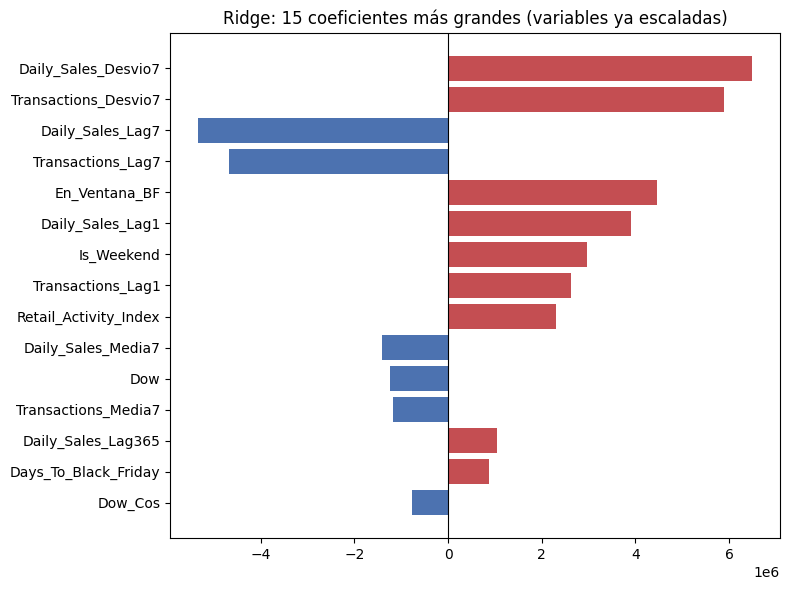

,0
Daily_Sales_Desvio7,6.494934e+06
Transactions_Desvio7,5.880560e+06
Daily_Sales_Lag7,-5.338607e+06
Transactions_Lag7,-4.672051e+06
En_Ventana_BF,4.463415e+06
Daily_Sales_Lag1,3.908787e+06
Is_Weekend,2.960327e+06
Transactions_Lag1,2.618133e+06
Retail_Activity_Index,2.311771e+06
Daily_Sales_Media7,-1.409775e+06


In [34]:
# Celda: coeficientes de Ridge
modelo_ridge = ridge.best_estimator_.named_steps["ridge"]
coef_ridge = pd.Series(modelo_ridge.coef_, index=X_train_val_imp.columns)
coef_ridge = coef_ridge.reindex(coef_ridge.abs().sort_values(ascending=False).index)

top_n = 15
fig, ax = plt.subplots(figsize=(8, 6))
top = coef_ridge.head(top_n)[::-1]
colores_coef = [PALETA[3] if v > 0 else PALETA[0] for v in top]
ax.barh(top.index, top.values, color=colores_coef)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Ridge: {top_n} coeficientes más grandes (variables ya escaladas)")
plt.tight_layout()
plt.show()

coef_ridge.head(top_n)

Los coeficientes más grandes de Ridge son variables autorregresivas de corto plazo
(`Daily_Sales_Desvio7`, `Transactions_Desvio7`, `Daily_Sales_Lag7`, `Daily_Sales_Lag1`) y la
cercanía a Black Friday (`En_Ventana_BF`, `Days_To_Black_Friday`), además de `Is_Weekend` y `Dow`,
que reflejan la estacionalidad semanal ya vista en el TP2.

Los signos de coeficientes individuales acá no se pueden leer de forma aislada: hay bastante
multicolinealidad entre lags y medias móviles de la misma serie (por ejemplo `Daily_Sales_Lag7` da
negativo pese a que uno esperaría que más venta hace 7 días se asocie con más venta hoy). Eso pasa
porque varias variables correlacionadas entre sí se reparten un efecto que en conjunto sí tiene
sentido, y Ridge no tiene forma de elegir cuál se queda con el peso.

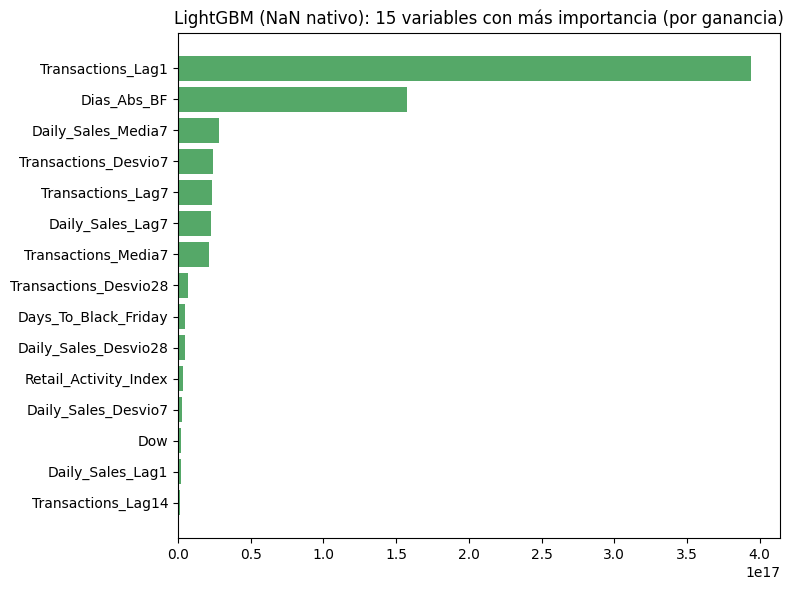

,gain,split
Transactions_Lag1,3.942958e+17,269
Dias_Abs_BF,1.576100e+17,135
Daily_Sales_Media7,2.838472e+16,147
Transactions_Desvio7,2.433389e+16,193
Transactions_Lag7,2.361829e+16,211
Daily_Sales_Lag7,2.260360e+16,260
Transactions_Media7,2.111815e+16,150
Transactions_Desvio28,7.076840e+15,154
Days_To_Black_Friday,5.045870e+15,49
Daily_Sales_Desvio28,4.920909e+15,200


In [37]:
# Celda: importancia de variables en LightGBM (NaN nativo)
modelo_lgbm = lgbm_nan.best_estimator_

imp_split = pd.Series(modelo_lgbm.booster_.feature_importance(importance_type="split"),
                      index=X_train_val_nan.columns)
imp_gain = pd.Series(modelo_lgbm.booster_.feature_importance(importance_type="gain"),
                     index=X_train_val_nan.columns)

top_n = 15
top_gain = imp_gain.sort_values(ascending=False).head(top_n)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_gain.index, top_gain.values, color=PALETA[2])
ax.set_title(f"LightGBM (NaN nativo): {top_n} variables con más importancia (por ganancia)")
plt.tight_layout()
plt.show()

pd.DataFrame({"gain": imp_gain, "split": imp_split}).sort_values("gain", ascending=False).head(top_n)

En LightGBM la importancia está mucho más concentrada: `Transactions_Lag1` y `Dias_Abs_BF`
(distancia absoluta a Black Friday, sin signo) juntas superan por lejos al resto de las variables,
tanto en `gain` como en `split`. Es una diferencia de fondo con Ridge: un árbol puede capturar de
un solo corte una combinación de variables correlacionadas, mientras que un modelo lineal tiene
que repartir ese mismo efecto entre varias.

También llama la atención que LightGBM prefiera la distancia absoluta a BF (`Dias_Abs_BF`, forma
de "V": el error es simétrico antes y después del evento) mientras Ridge usa la distancia con
signo más el flag `En_Ventana_BF`, porque una suma lineal no puede replicar bien una forma en V con
una sola variable numérica sin combinarla con otra.

### Cierre del punto g)

Ambos modelos coinciden entre sí y con los hallazgos del TP2: se apoyan fuerte en variables
autorregresivas de corto plazo y en la cercanía a Black Friday. `Retail_Activity_Index` aparece
con peso relevante en los dos, pero conviene aclarar la diferencia entre importancia predictiva y
causalidad: como ya se advirtió en el TP2, es una variable que se mueve con el paso del tiempo
junto con las ventas (ambas crecen con la tendencia del negocio), no hay evidencia de que el
índice cause las ventas. Que una variable sea importante para predecir no significa que el negocio
pueda intervenir sobre ella para cambiar el resultado.

## h) Predicción desde un único origen

Hasta acá, cada predicción de 2024 usaba información real de días anteriores (esquema "un paso
adelante"): para predecir el 5 de julio, el modelo tiene el dato real del 4 de julio, de hace una
semana, de hace un año, etc. Es razonable si todos los días se reciben datos frescos.

Este punto plantea un escenario distinto: solo se sabe lo que pasó hasta el 31 de diciembre de
2023, y hay que proyectar los 366 días de 2024 de una sola vez, sin recibir datos reales en el
medio. Es el escenario típico de un presupuesto anual armado con anticipación.

La diferencia clave es qué pasa con los lags de corto plazo: al predecir el 2 de enero de 2024, el
lag de 1 día (1 de enero) es un dato real. Pero al predecir, digamos, el 15 de marzo, el lag de 1
día ya cae dentro de 2024 y no hay dato real: hay que usar la predicción que el propio modelo hizo
para ese día. Esto se llama predicción **recursiva**: cada predicción se retroalimenta con
predicciones anteriores del mismo modelo, en vez de con datos reales, y los errores se pueden ir
acumulando de un día al siguiente.

El lag de 365 días es la excepción: como siempre apunta a un año antes, durante todo 2024 sigue
disponible como dato real (apunta a 2023).

### Por qué se sacan las variables de Transactions

En el esquema recursivo, no solo `Daily_Sales` es desconocida hacia adelante: `Transactions`
también lo es, y no hay ningún modelo entrenado para pronosticarla. Antes de decidir qué hacer,
chequeamos qué tan parecida es a `Daily_Sales`.

In [39]:
# Celda: correlación entre Daily_Sales y Transactions, para justificar sacar
# las columnas de Transactions del modelo del punto h
print("Correlación de Pearson:", daily["Daily_Sales"].corr(daily["Transactions"]))
print("Correlación de Spearman:", daily["Daily_Sales"].corr(daily["Transactions"], method="spearman"))

Correlación de Pearson: 0.9924393063059527
Correlación de Spearman: 0.9293139821922982


In [40]:
# Celda: correlación entre cada lag/rolling de Daily_Sales y su equivalente de Transactions,
# para confirmar que sacar las columnas de Transactions del modelo del punto h no pierde
# información relevante (cada una tiene una "gemela" casi idéntica en Daily_Sales)
pares = ["Lag1", "Lag7", "Lag14", "Lag28", "Lag365", "Media7", "Desvio7", "Media28", "Desvio28"]

correlaciones = pd.Series({
    p: daily[f"Daily_Sales_{p}"].corr(daily[f"Transactions_{p}"]) for p in pares
})
correlaciones.round(3)

,0
Lag1,0.992
Lag7,0.993
Lag14,0.993
Lag28,0.993
Lag365,0.998
Media7,0.992
Desvio7,0.995
Media28,0.987
Desvio28,0.995


La correlación entre `Daily_Sales` y `Transactions` es prácticamente perfecta (Pearson 0,992,
Spearman 0,929), y lo mismo pasa entre cada lag o rolling de una y su equivalente de la otra
(entre 0,987 y 0,998). Es decir, casi toda la información que aportarían las variables de
`Transactions` ya está contenida en las de `Daily_Sales`.

Con esto, se descartan dos alternativas más costosas (congelar `Transactions` en su último valor
real de 2023, o armar un mini-pronóstico aparte solo para esa variable) y se opta por la más
simple: sacar directamente las 9 columnas de `Transactions_*` del modelo de este punto, confiando
en que `Daily_Sales_*` ya trae casi la misma señal.

Reentrenamos LightGBM (NaN nativo) y Ridge (flag + imputación) sobre este nuevo conjunto de 24
variables (`FEATURES_H`), usando los mismos hiperparámetros ya elegidos en el punto d): no hace
falta correr de nuevo el `GridSearchCV`, alcanza con reentrenar sobre las columnas nuevas.

In [41]:
# Celda: variables y modelos para el punto h (sin Transactions_*)
COLUMNAS_TRANSACTIONS = [c for c in FEATURES if c.startswith("Transactions_")]
FEATURES_H = [c for c in FEATURES if c not in COLUMNAS_TRANSACTIONS]
print(f"Se sacan {len(COLUMNAS_TRANSACTIONS)} columnas de Transactions. Quedan {len(FEATURES_H)} features.")

X_train_val_h_nan = X_train_val_nan[FEATURES_H].copy()

COLUMNAS_CON_HISTORIA_INCOMPLETA_H = [c for c in FEATURES_H if X_train_val_h_nan[c].isna().any()]
X_train_val_h_imp = X_train_val_h_nan.copy()
medianas_h = {}
for col in COLUMNAS_CON_HISTORIA_INCOMPLETA_H:
    medianas_h[col] = X_train_val_h_nan[col].median()
    X_train_val_h_imp[f"{col}_Disponible"] = X_train_val_h_nan[col].notna().astype(int)
    X_train_val_h_imp[col] = X_train_val_h_nan[col].fillna(medianas_h[col])

# Mismos hiperparametros ya elegidos en el punto d, solo cambia el conjunto de variables
lgbm_h = LGBMRegressor(random_state=42, verbose=-1, **lgbm_nan.best_params_)
lgbm_h.fit(X_train_val_h_nan, y_train_val)

ridge_h = make_pipeline(StandardScaler(), Ridge(random_state=42, alpha=ridge.best_params_["ridge__alpha"]))
ridge_h.fit(X_train_val_h_imp, y_train_val)

Se sacan 9 columnas de Transactions. Quedan 24 features.


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridge', Ridge(alpha=10.0, random_state=42))])

### El bucle recursivo

Para cada una de las 366 fechas de 2024, en orden: tomamos las variables que se conocen de
antemano (calendario, cercanía a BF, contexto económico) directo de la tabla de test, recalculamos
las variables autorregresivas a partir de una "historia" que se va actualizando con cada
predicción nueva, y guardamos la predicción.

Cada modelo tiene su propia historia, independiente del otro: LightGBM se retroalimenta solo con
sus propias predicciones, y Ridge con las suyas, para que un modelo no termine ayudando (o
perjudicando) al otro.

In [42]:
# Celda: prediccion recursiva de los 366 dias de 2024, un dia a la vez
CONOCIDAS_H = [c for c in FEATURES_H if not c.startswith("Daily_Sales_")]

def features_autoregresivas(historia, fecha):
    fila = {}
    for lag in [1, 7, 14, 28, 365]:
        fila[f"Daily_Sales_Lag{lag}"] = historia.loc[fecha - pd.Timedelta(days=lag)]
    fila["Daily_Sales_Media7"] = historia.iloc[-7:].mean()
    fila["Daily_Sales_Desvio7"] = historia.iloc[-7:].std()
    fila["Daily_Sales_Media28"] = historia.iloc[-28:].mean()
    fila["Daily_Sales_Desvio28"] = historia.iloc[-28:].std()
    return fila

historia_lgbm = daily.set_index("Purchase_Date")["Daily_Sales"].loc[:"2023-12-31"].copy()
historia_ridge = historia_lgbm.copy()

pred_lgbm_h, pred_ridge_h = [], []

for fecha in test["Purchase_Date"]:
    conocidas = test.loc[test["Purchase_Date"] == fecha, CONOCIDAS_H].iloc[0].to_dict()

    fila_lgbm = {**conocidas, **features_autoregresivas(historia_lgbm, fecha)}
    x_nan = pd.DataFrame([fila_lgbm])[FEATURES_H]
    p_lgbm = lgbm_h.predict(x_nan)[0]

    fila_ridge = {**conocidas, **features_autoregresivas(historia_ridge, fecha)}
    x_imp = pd.DataFrame([fila_ridge])[FEATURES_H]
    for col in COLUMNAS_CON_HISTORIA_INCOMPLETA_H:
        x_imp[f"{col}_Disponible"] = 1
    x_imp = x_imp[X_train_val_h_imp.columns]
    p_ridge = ridge_h.predict(x_imp)[0]

    historia_lgbm.loc[fecha] = p_lgbm
    historia_ridge.loc[fecha] = p_ridge
    pred_lgbm_h.append(p_lgbm)
    pred_ridge_h.append(p_ridge)

pred_h = pd.DataFrame({
    "Purchase_Date": test["Purchase_Date"].values,
    "Real": y_test.values,
    "LGBM_h": pred_lgbm_h,
    "Ridge_h": pred_ridge_h,
})
pred_h.head()

,Purchase_Date,Real,LGBM_h,Ridge_h
0,2024-01-01,10264703,4.133888e+06,1.129663e+07
1,2024-01-02,10198877,1.349432e+07,7.465335e+06
2,2024-01-03,11022144,1.129501e+07,8.463947e+06
3,2024-01-04,10355256,1.047521e+07,1.159117e+07
4,2024-01-05,10705226,1.138459e+07,1.258635e+07


La tabla muestra las primeras predicciones de enero de 2024: como recién arranca el esquema
recursivo, todavía coinciden casi en su totalidad con lo que haría el esquema de un paso (los lags
cortos siguen siendo datos reales de fines de 2023).

### Real vs. predicción recursiva

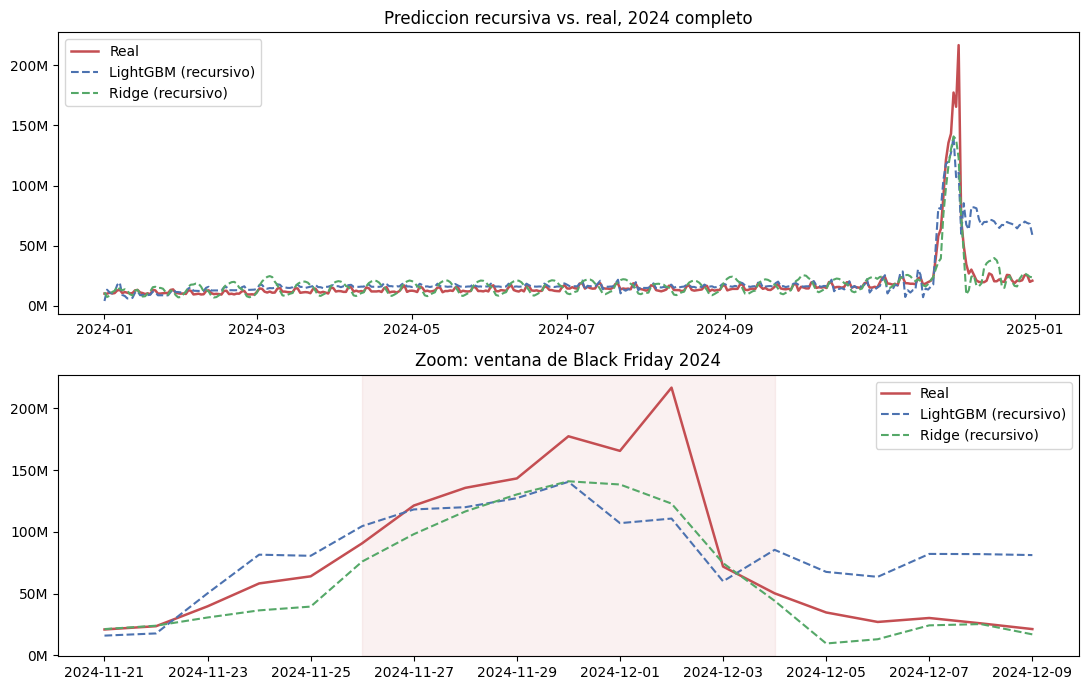

In [43]:
# Celda: real vs. predicciones recursivas (2024 completo y zoom en Black Friday)
pred_h["En_Ventana_BF"] = test["En_Ventana_BF"].values

ventana_h = pred_h[pred_h["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom_h = pred_h[
    (pred_h["Purchase_Date"] >= ventana_h["Purchase_Date"].min() - margen) &
    (pred_h["Purchase_Date"] <= ventana_h["Purchase_Date"].max() + margen)
]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, datos, titulo in [(axes[0], pred_h, "Prediccion recursiva vs. real, 2024 completo"),
                          (axes[1], zoom_h, "Zoom: ventana de Black Friday 2024")]:
    ax.plot(datos["Purchase_Date"], datos["Real"], label="Real", color=PALETA[3], linewidth=1.8)
    ax.plot(datos["Purchase_Date"], datos["LGBM_h"], label="LightGBM (recursivo)", color=PALETA[0], linestyle="--")
    ax.plot(datos["Purchase_Date"], datos["Ridge_h"], label="Ridge (recursivo)", color=PALETA[2], linestyle="--")
    ax.set_title(titulo)
    millones(ax)
    ax.legend()
axes[1].axvspan(ventana_h["Purchase_Date"].min(), ventana_h["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
plt.tight_layout()
plt.show()

En el gráfico se nota que LightGBM empieza a subir antes de tiempo a comienzos de noviembre, y que
después del pico de Black Friday se queda pegado en valores altos (65 a 80 millones) durante
varias semanas, mientras la venta real ya volvió a niveles de 20 a 30 millones. Ridge reacciona
más despacio al pico pero se recupera más rápido después.

### Cómo crece el error con el horizonte

Miramos el error (con una ventana móvil de 14 días, para suavizar el ruido día a día) en función
de cuántos días pasaron desde el origen de la predicción, el 31 de diciembre de 2023.

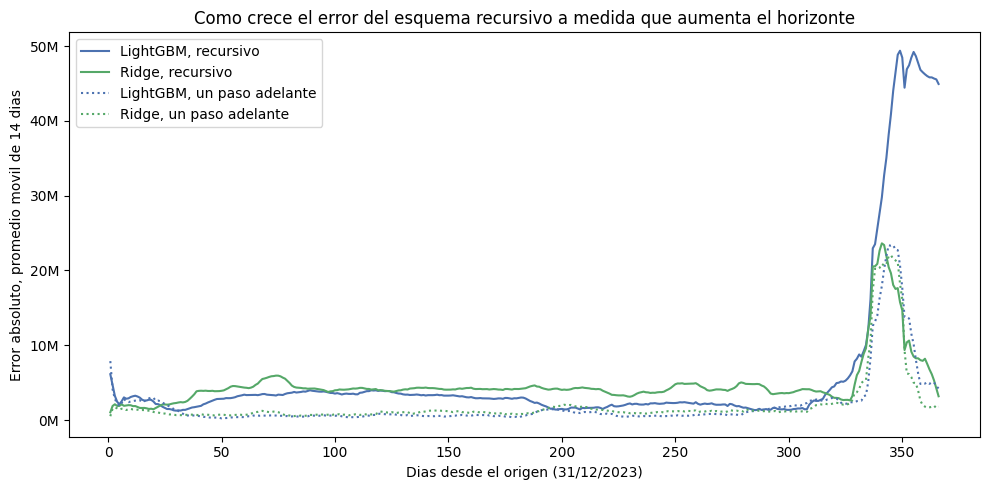

In [44]:
# Celda: como crece el error a medida que aumenta el horizonte (dias desde el 31/12/2023)
pred_h["Horizonte"] = (pred_h["Purchase_Date"] - pd.Timestamp("2023-12-31")).dt.days
pred_h["Real_LGBM_onestep"] = pred_test["LGBM_NaN"].values  # el de "un paso" del punto e, misma fecha
pred_h["Real_Ridge_onestep"] = pred_test["Ridge"].values

def error_movil_por_horizonte(real, pred, ventana=14):
    err = (real - pred).abs()
    return err.rolling(ventana, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["LGBM_h"]),
        label="LightGBM, recursivo", color=PALETA[0])
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Ridge_h"]),
        label="Ridge, recursivo", color=PALETA[2])
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Real_LGBM_onestep"]),
        label="LightGBM, un paso adelante", color=PALETA[0], linestyle=":")
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Real_Ridge_onestep"]),
        label="Ridge, un paso adelante", color=PALETA[2], linestyle=":")
ax.set_xlabel("Dias desde el origen (31/12/2023)")
ax.set_ylabel("Error absoluto, promedio movil de 14 dias")
ax.set_title("Como crece el error del esquema recursivo a medida que aumenta el horizonte")
millones(ax)
ax.legend()
plt.tight_layout()
plt.show()

Las cuatro curvas (LightGBM y Ridge, recursivo y un paso) se mantienen bajas y parejas durante
casi todo el año, hasta cerca del día 320 (fines de octubre), y recién ahí se disparan todas
juntas cerca de Black Friday. Esto es importante: el error **no** se acumula de forma gradual a lo
largo del año por el solo hecho de ser recursivo, es un fenómeno concentrado en el evento.
LightGBM recursivo llega a un pico de error móvil de alrededor de 50 millones y tarda varios días
en bajar de 45 millones, mientras que Ridge recursivo y las dos curvas de un paso llegan a un pico
menor (alrededor de 23 millones) y bajan más rápido.

In [45]:
# Celda: metricas globales, recursivo vs. un paso adelante
def metricas_h(real, pred):
    return {
        "RMSE (M)": np.sqrt(np.mean((real - pred) ** 2)) / 1e6,
        "MAE (M)": np.mean(np.abs(real - pred)) / 1e6,
    }

pd.DataFrame({
    "LGBM recursivo": metricas_h(pred_h["Real"], pred_h["LGBM_h"]),
    "LGBM un paso": metricas_h(pred_h["Real"], pred_h["Real_LGBM_onestep"]),
    "Ridge recursivo": metricas_h(pred_h["Real"], pred_h["Ridge_h"]),
    "Ridge un paso": metricas_h(pred_h["Real"], pred_h["Real_Ridge_onestep"]),
}).round(2)

,LGBM recursivo,LGBM un paso,Ridge recursivo,Ridge un paso
RMSE (M),14.88,5.94,8.01,6.85
MAE (M),6.81,2.07,4.79,2.07


Comparando el error global de los dos esquemas: LightGBM empeora fuerte al pasar a recursivo
(RMSE de 5,94M a 14,88M, +150%), mientras que Ridge se degrada mucho menos (de 6,85M a 8,01M,
+17%). El ranking se invierte respecto del punto e), donde LightGBM ganaba: acá gana Ridge, y por
margen amplio.

Por qué le cuesta más a LightGBM: un árbol de decisión no extrapola, solo puede predecir valores
que ya vio en el entrenamiento repartidos entre sus hojas. Cuando el esquema recursivo empieza a
alimentar al modelo con sus propias predicciones (que pueden salirse del rango que el árbol
conoce, sobre todo alrededor de un evento tan grande como Black Friday), LightGBM cae en la hoja
más parecida que tiene disponible, que no necesariamente es la correcta. Ridge, al ser una suma
lineal, extrapola de forma más suave aunque tampoco sea perfecta.

In [46]:
# Celda: desempeño por zona del esquema recursivo (mismas zonas del punto f)
pred_h["Dias_BF"] = test["Days_To_Black_Friday"].values
pred_h["Zona"] = np.select(
    [pred_h["En_Ventana_BF"] == 1, pred_h["Dias_BF"] > 5],
    ["Ventana BF", "Después de la ventana"],
    default="Resto del año",
)

modelos_h = ["LGBM_h", "Ridge_h"]
zonas = ["Ventana BF", "Después de la ventana", "Resto del año"]

def por_zona_h(f):
    filas = {"Global": {m: f(pred_h["Real"], pred_h[m]) for m in modelos_h}}
    for z in zonas:
        g = pred_h[pred_h["Zona"] == z]
        filas[z] = {m: f(g["Real"], g[m]) for m in modelos_h}
    return pd.DataFrame(filas)

rmse_h = lambda r, p: np.sqrt(np.mean((r - p) ** 2)) / 1e6
mae_h = lambda r, p: np.mean(np.abs(r - p)) / 1e6

print("RMSE recursivo (M)"); display(por_zona_h(rmse_h).round(2))
print("MAE recursivo (M)"); display(por_zona_h(mae_h).round(2))

RMSE recursivo (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_h,14.88,44.85,46.64,3.55
Ridge_h,8.01,36.83,9.38,5.19


MAE recursivo (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_h,6.81,33.01,46.33,2.86
Ridge_h,4.79,26.26,6.81,4.03


El desglose por zona confirma la hipótesis del gráfico: en la ventana de BF ambos modelos
empeoran de forma parecida respecto del esquema de un paso (LightGBM 28,30M a 44,85M de RMSE,
Ridge 41,04M a 36,83M, este último incluso mejora un poco), pero es **después** de la ventana
donde se abre la brecha: LightGBM pasa de 13,54M a 46,64M de RMSE (se degrada mucho), mientras
Ridge pasa de 6,24M a 9,38M (se degrada bastante menos). Es la misma cicatriz post-BF que ya se
había visto en el esquema de un paso (punto f), pero acá el efecto es mucho más fuerte porque el
modelo no tiene la oportunidad de corregirse con un dato real al día siguiente: sigue
alimentándose de sus propias predicciones equivocadas.

### Cierre del punto h)

El escenario recursivo deja un hallazgo central: Ridge, el modelo más simple, es mucho más
robusto que LightGBM cuando hay que proyectar sin recibir datos reales en el camino. La razón de
fondo es la misma en los tres fenómenos que aparecen en este punto: las variables autorregresivas
dejan de ser datos reales y pasan a ser predicciones del propio modelo, con poca práctica (solo
dos Black Friday en el entrenamiento) para saber cuánto pesarlas, y un árbol en particular no sabe
qué hacer cuando esas variables se salen del rango que conoció en el entrenamiento. Para un caso
de uso real como un presupuesto anual, esto sugiere preferir el modelo más simple, aunque pierda
contra el boosting en el esquema de un paso.

## Conclusión general de la Parte 1

Los modelos supervisados (LightGBM y Ridge) superan claramente a los dos baselines en el esquema
principal de predicción a un paso adelante, tanto en el desempeño global (punto e) como en Black
Friday específicamente (punto f), aunque ningún modelo gana en todas las zonas: LightGBM
representa mejor el pico del evento, Ridge y el SARIMA son más confiables en las semanas
posteriores.

Ambos modelos se apoyan en las mismas señales (autorregresivas de corto plazo y cercanía a Black
Friday), coincidiendo con lo que ya había mostrado el TP2, aunque LightGBM concentra esa señal en
pocas variables y Ridge la reparte entre muchas correlacionadas (punto g).

El escenario recursivo del punto h) muestra que este tipo de modelos no envejece igual: Ridge se
degrada apenas al pasar de un esquema de un paso a uno recursivo (+17% de RMSE), mientras que
LightGBM se degrada mucho más (+150%), sobre todo en las semanas posteriores a Black Friday,
porque un árbol no extrapola bien frente a valores que rompen el rango visto en el entrenamiento.
Es un hallazgo con implicancia práctica: para un uso como presupuesto anual (que necesita el
esquema recursivo), un modelo lineal más simple puede ser la opción más robusta, aunque pierda
contra el boosting en el escenario de predicción día a día con datos frescos.